<a href="https://colab.research.google.com/github/Squad-Dorothy-Vaughan/desafio-final-bootcamp/blob/main/Desafio_final_desempenho_academico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

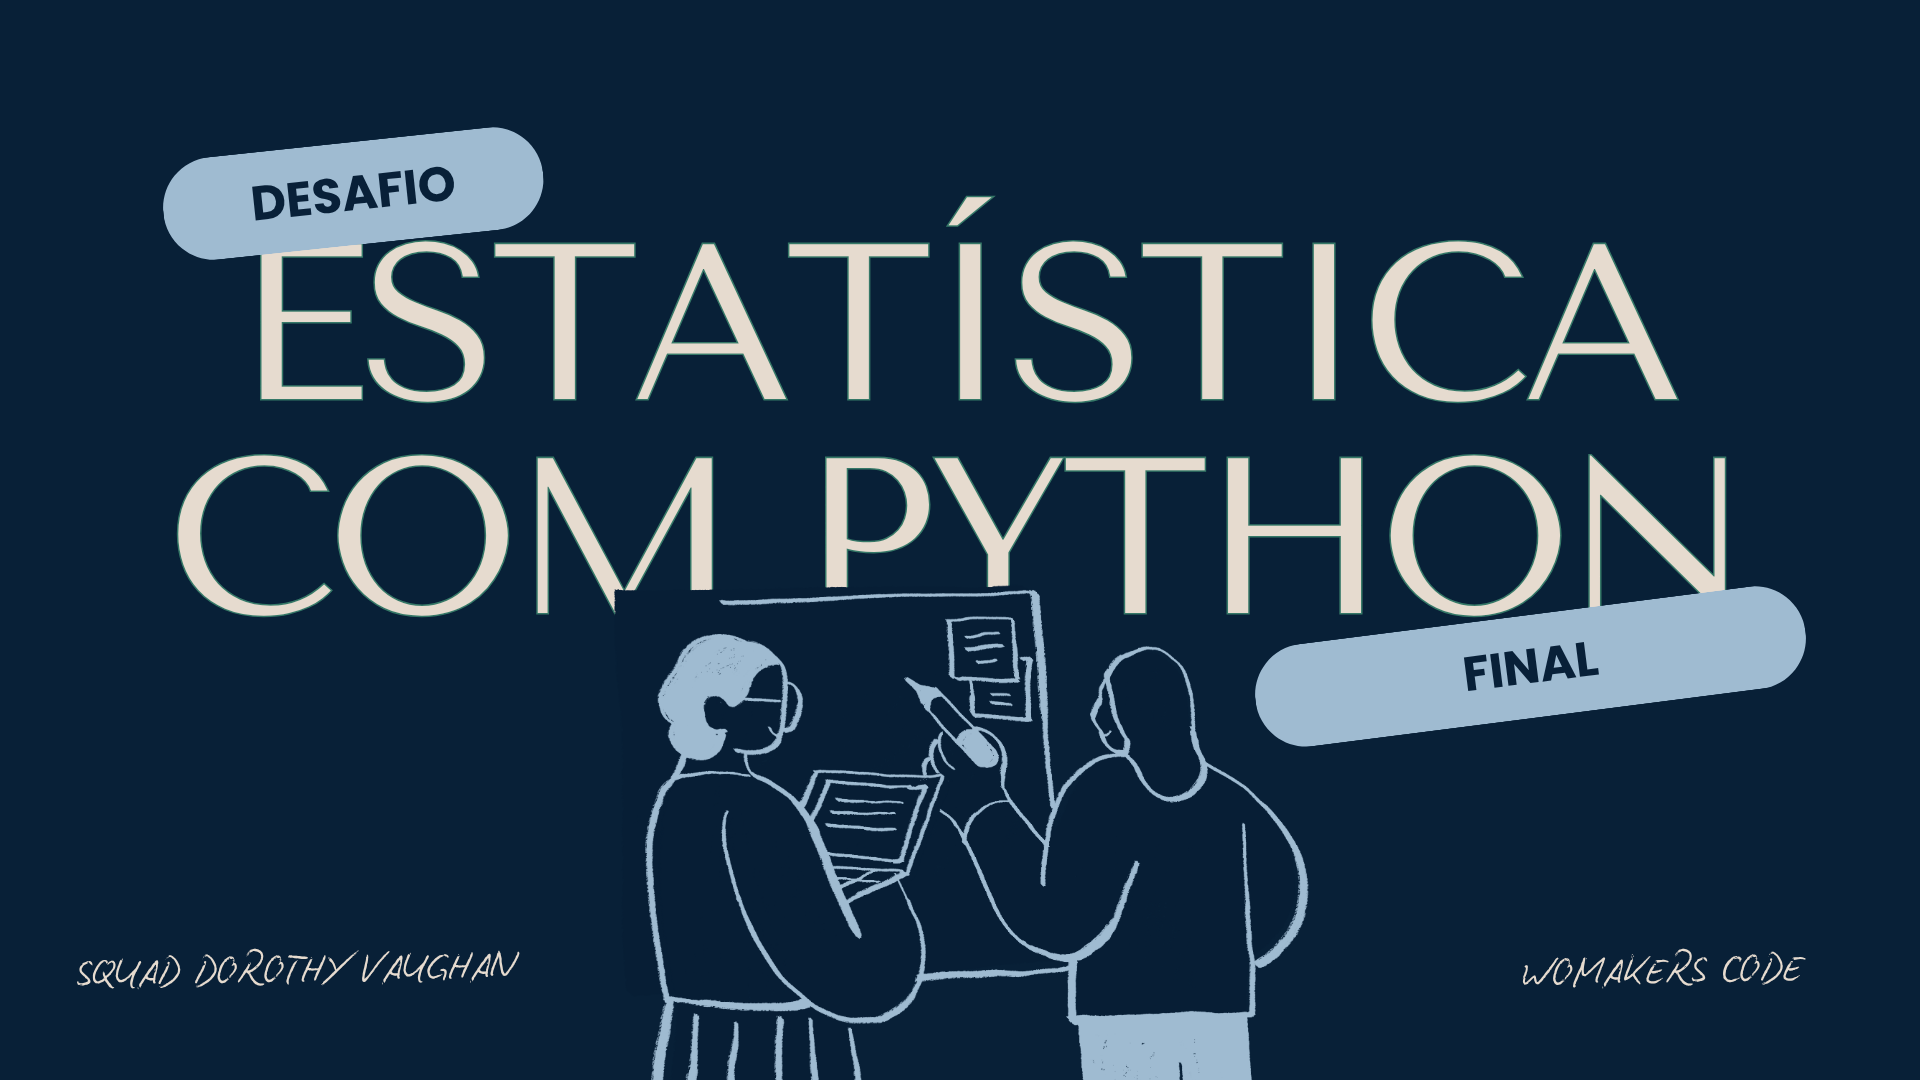

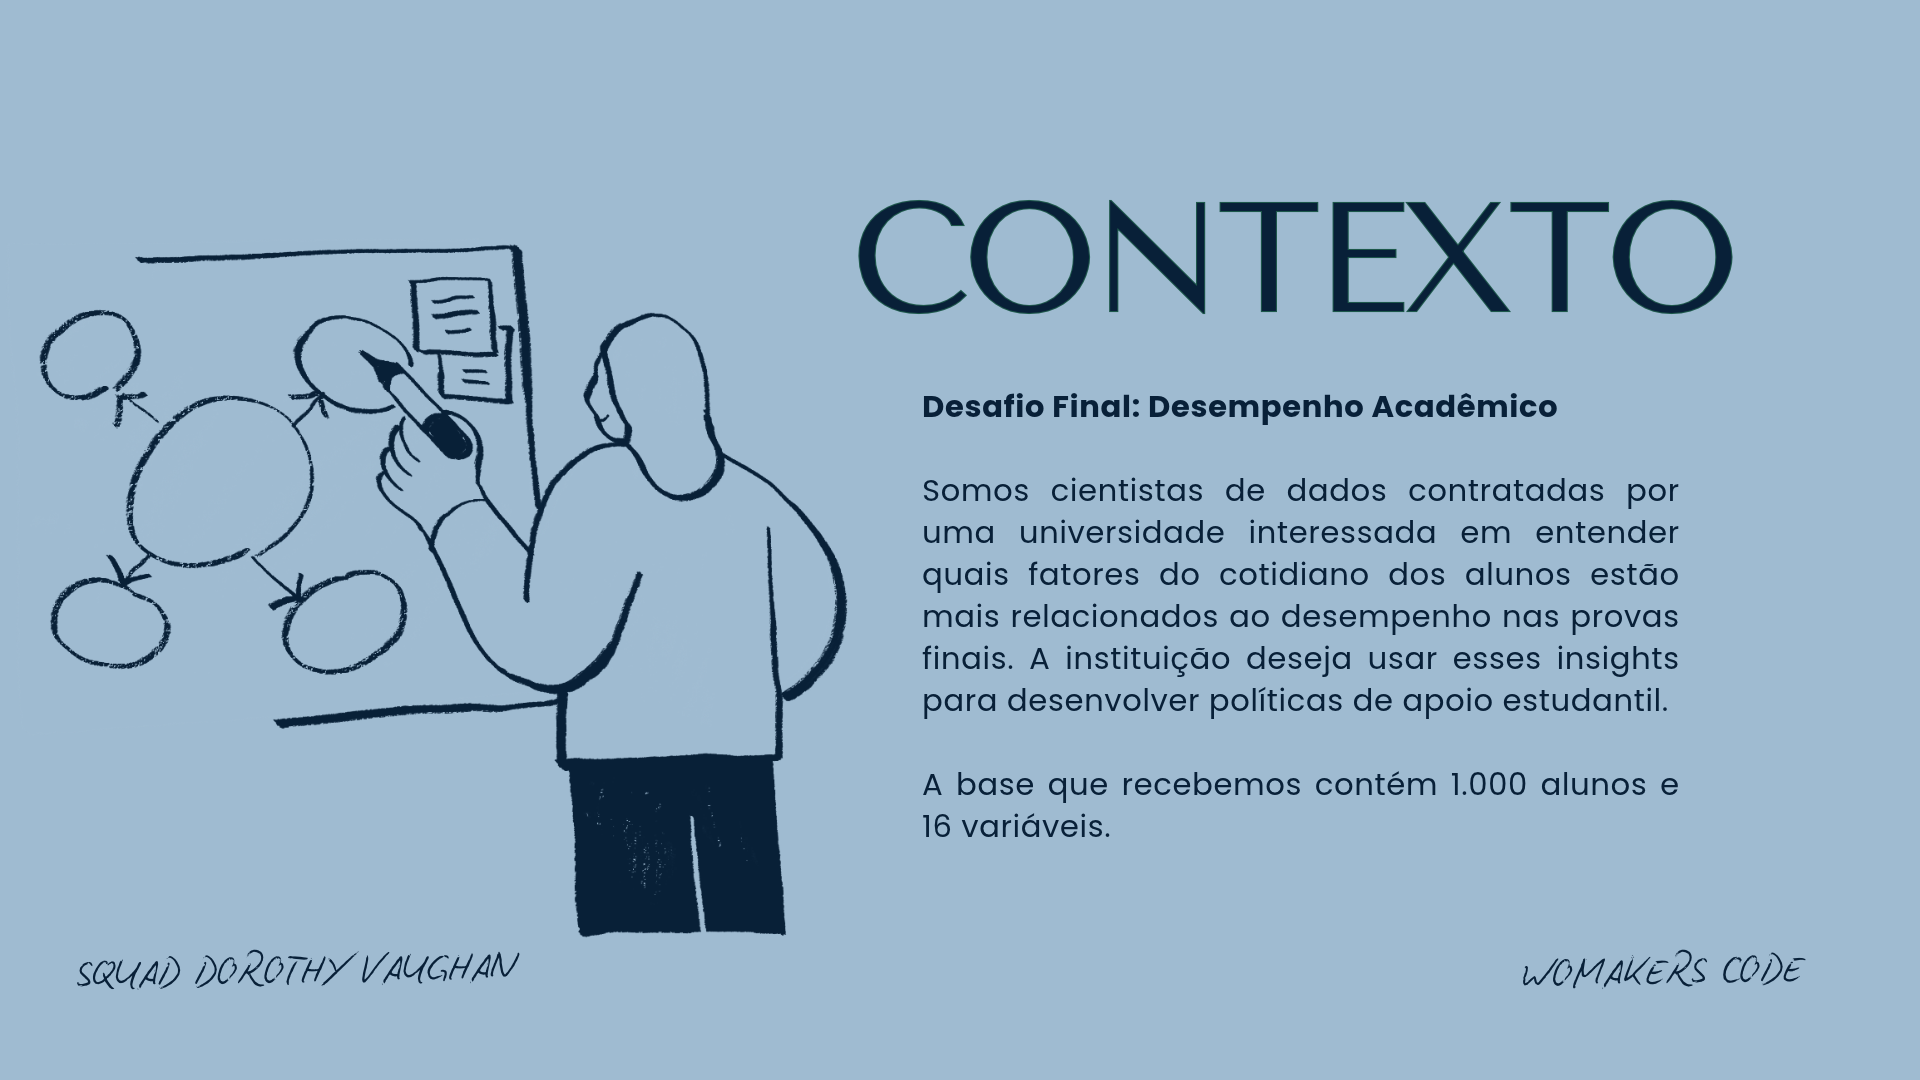

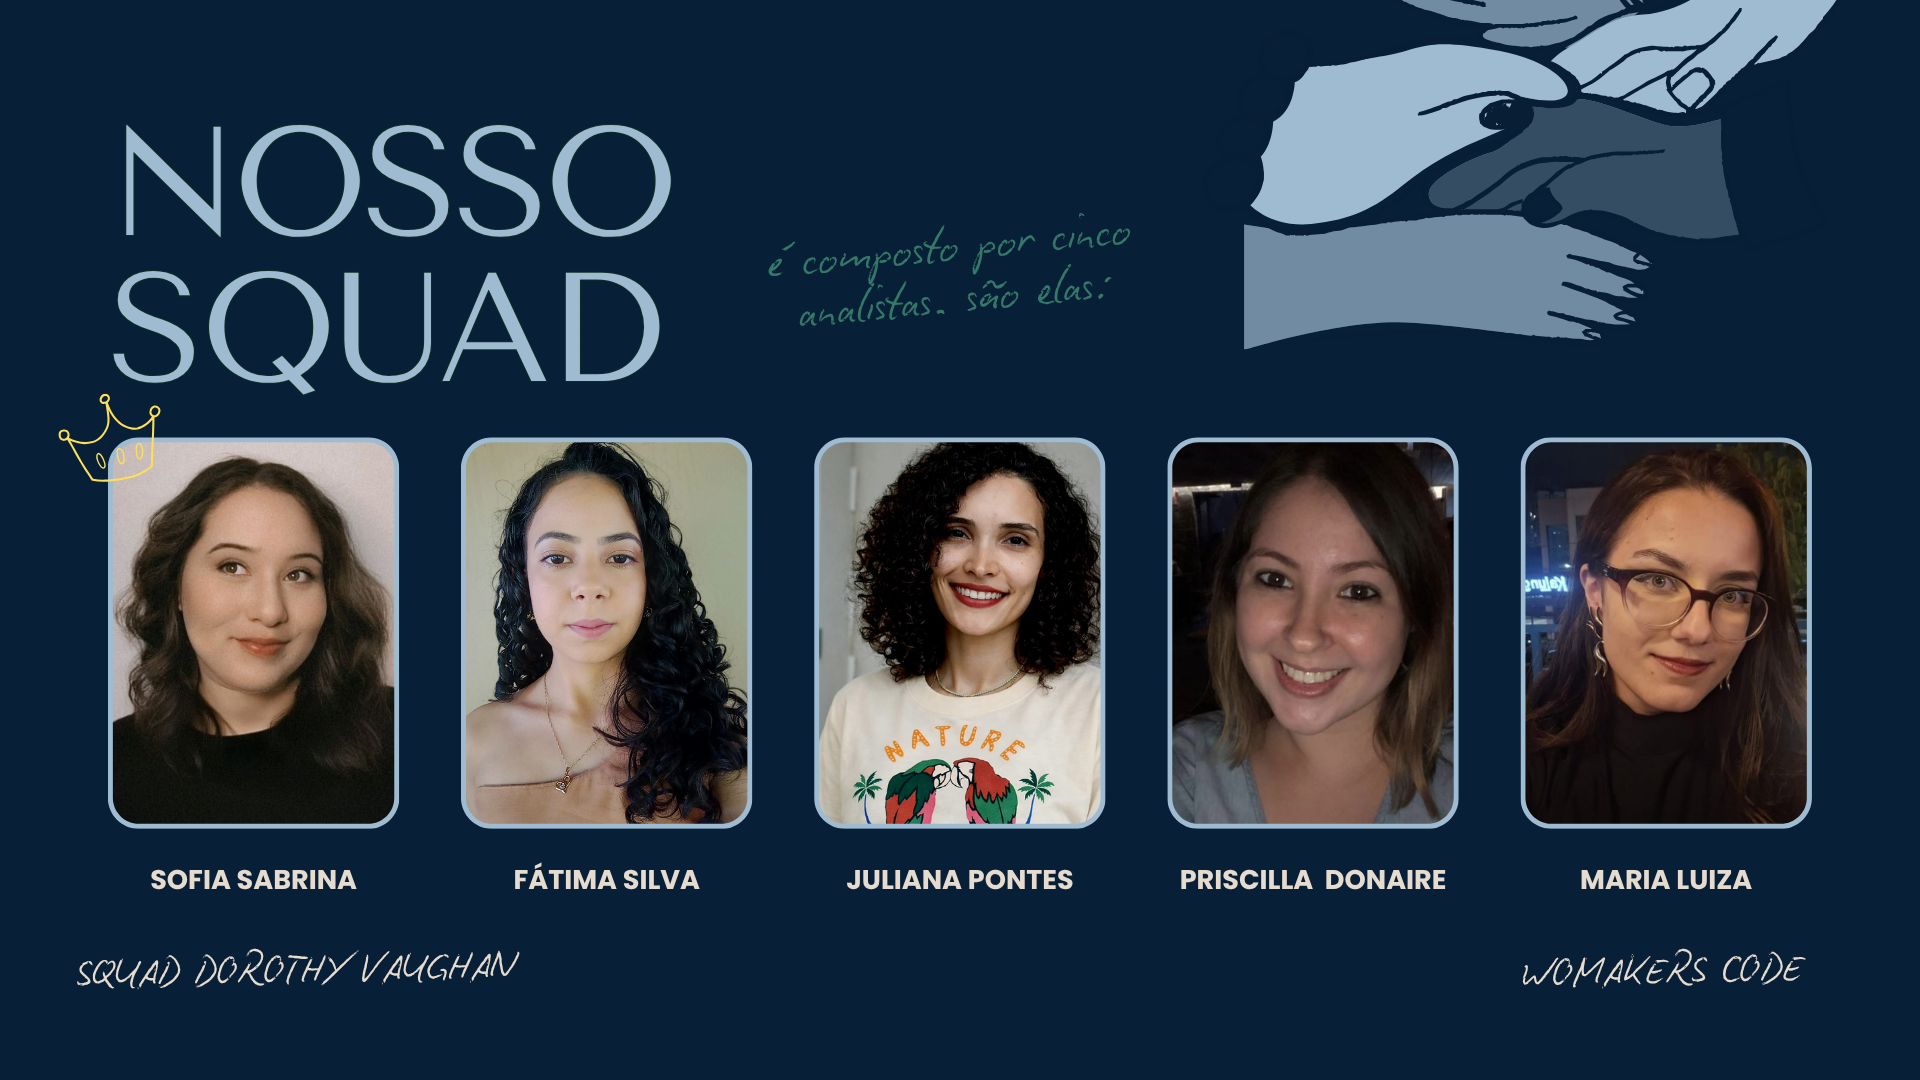

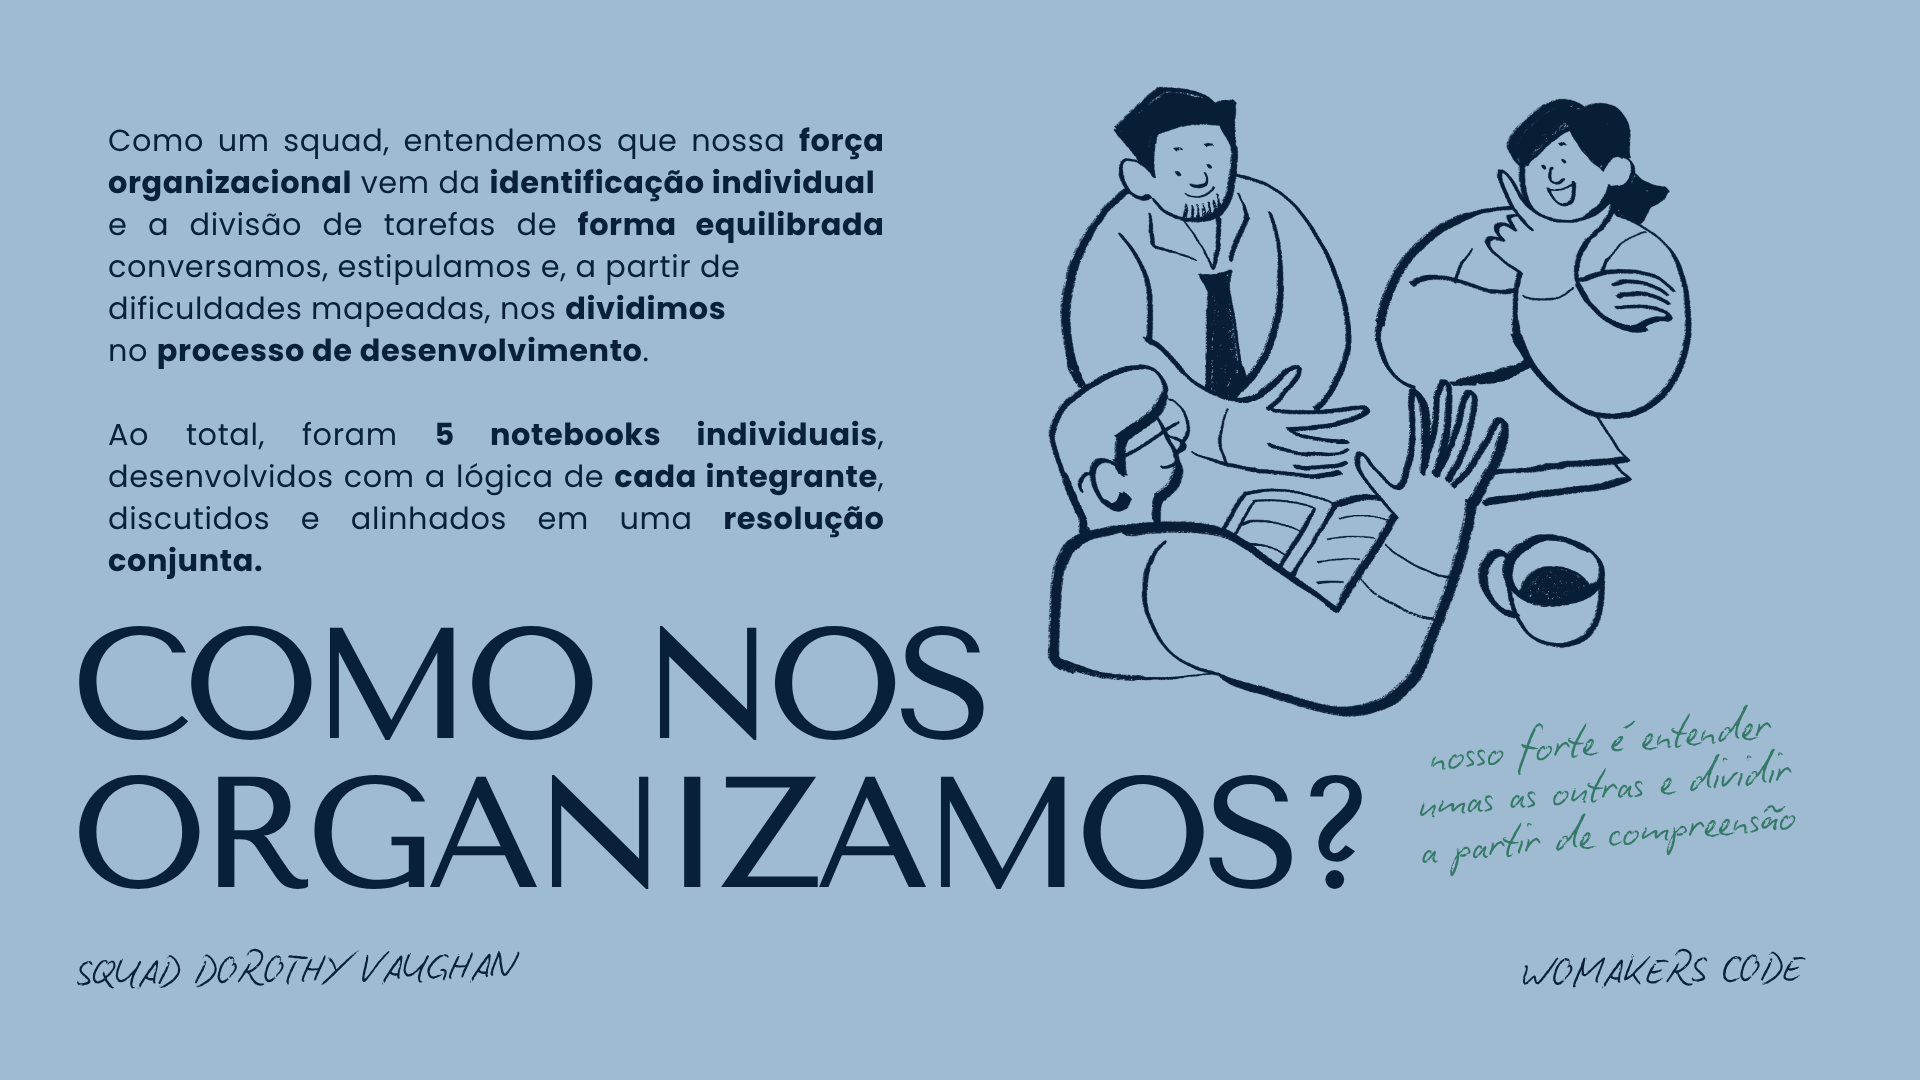

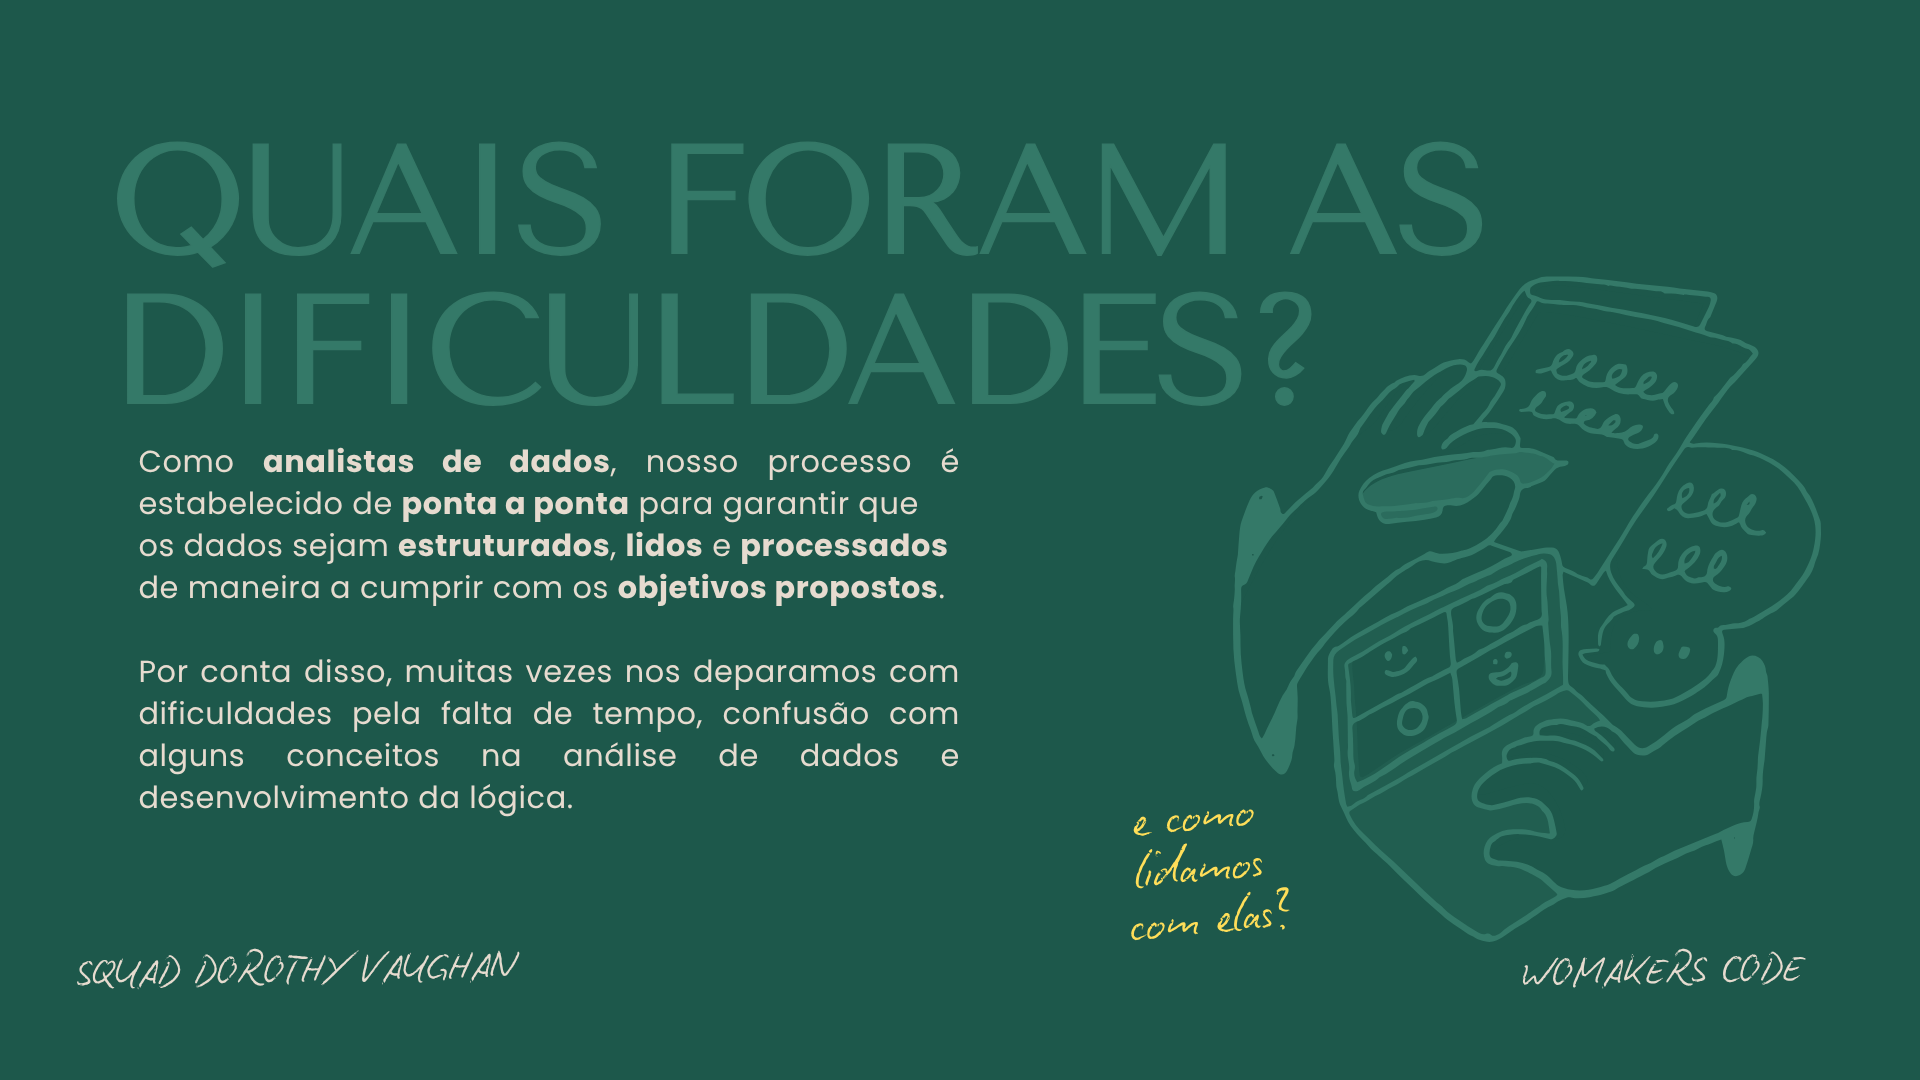

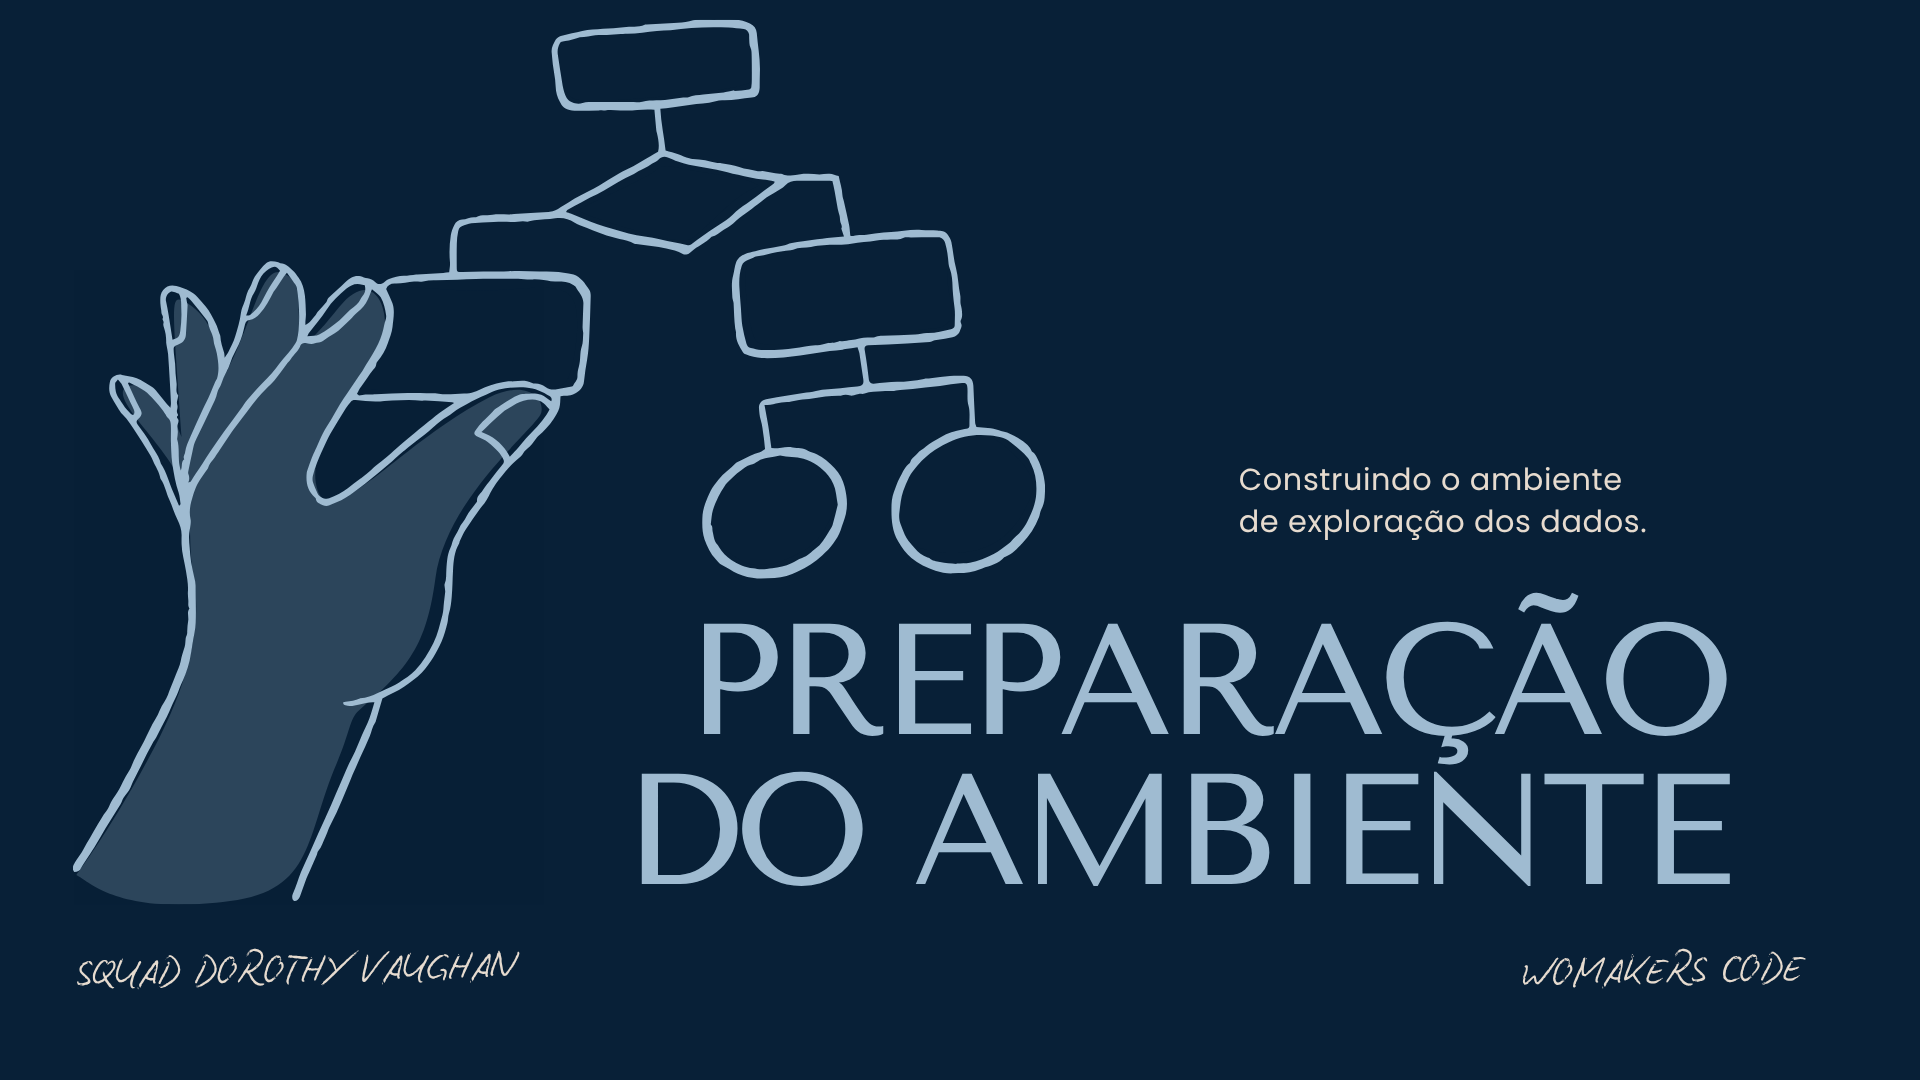

## 1. Preparação e tratamento dos dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Azul identifica o que puxa a nota para cima, vermelho o que puxa para baixo.
PALETA = ["#2F6690", "#3A7CA5", "#81C3D7", "#D9594C", "#F4A259"]
AZUL, AZUL_CLARO, VERMELHO, LARANJA = "#2F6690", "#81C3D7", "#D9594C", "#F4A259"

sns.set_theme(style="whitegrid", palette=PALETA)
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

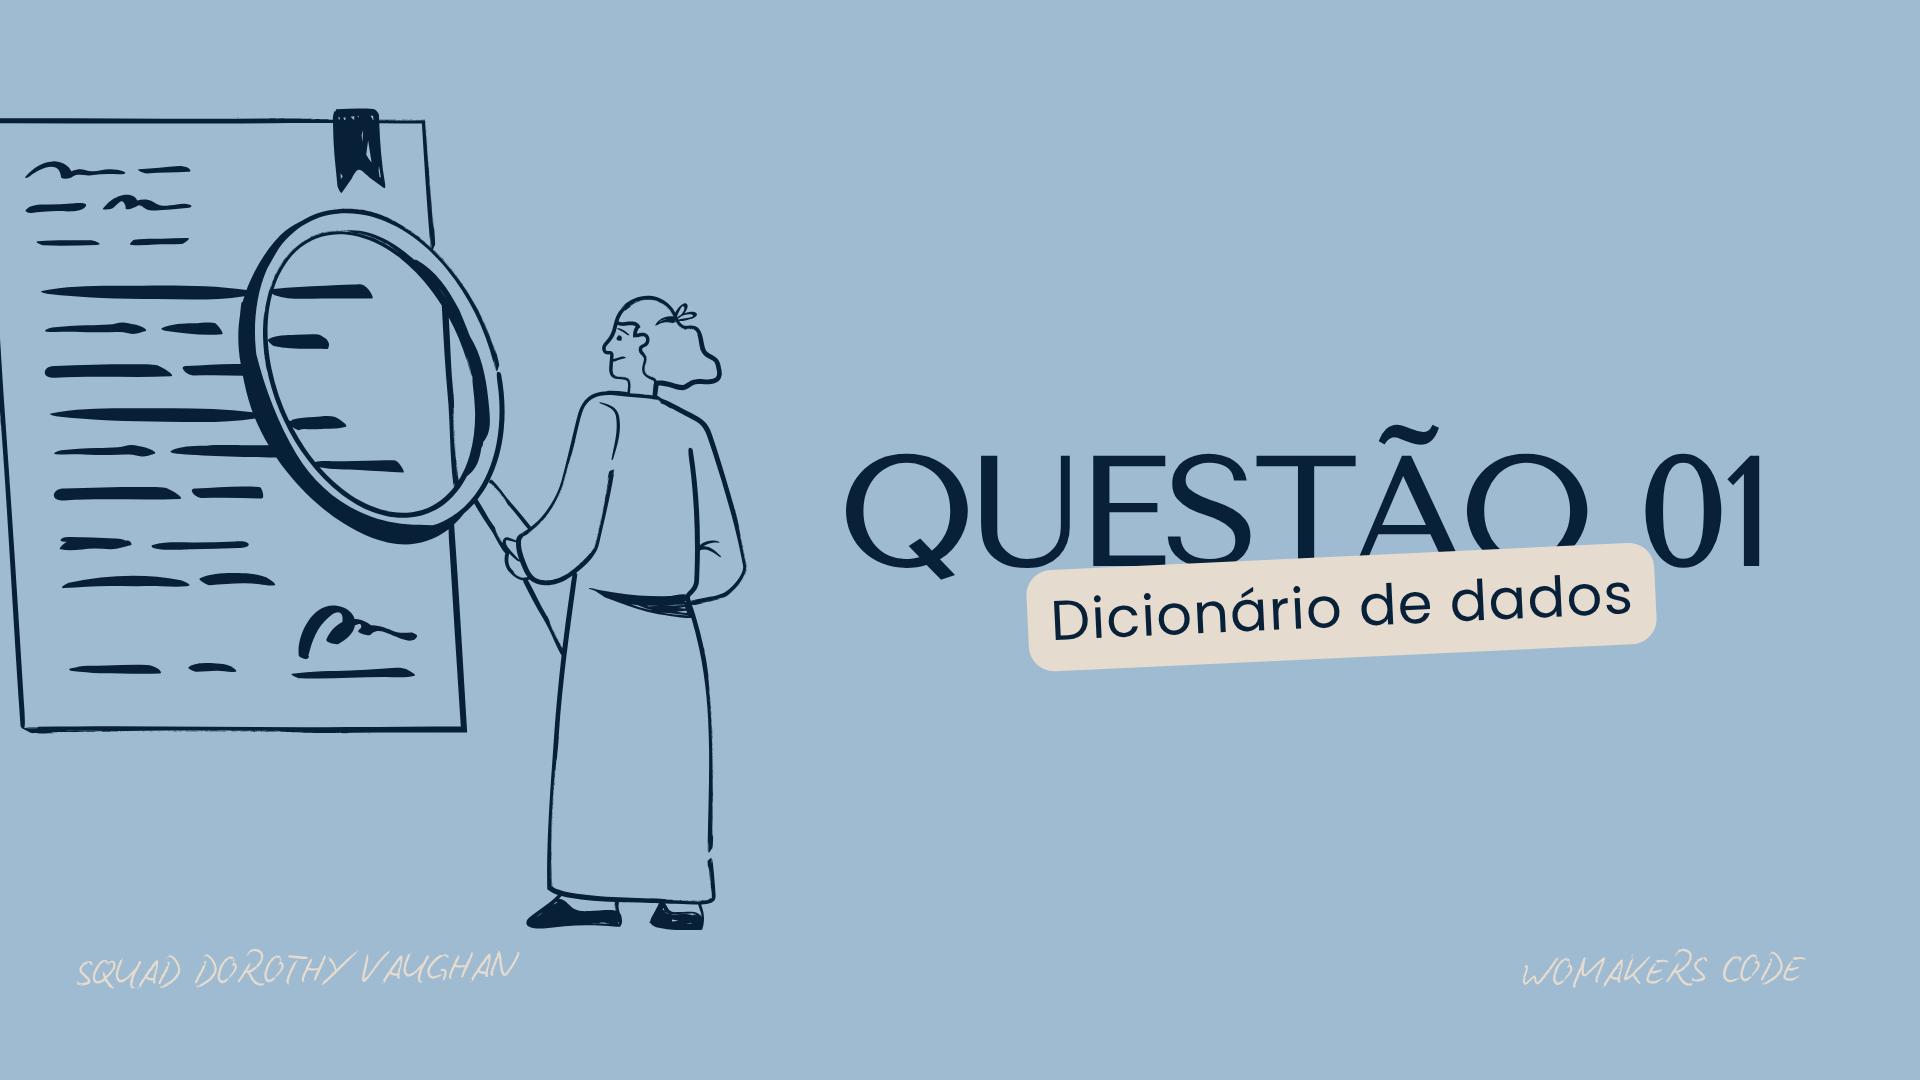

### Dicionário de Dados

| Variável Original | Tradução | Tipo Estatístico | Tipo Python | Descrição e Valores |
|---|---|---|---|---|
| `student_id` | ID do Estudante | Categórico Nominal | `object` | Identificador único do aluno (S1000 a S1999) |
| `age` | Idade | Numérico Discreto | `int64` | Idade do estudante em anos completos (17 a 24 anos) |
| `gender` | Gênero | Categórico Nominal | `object` | Gênero autodeclarado: `Female` (Feminino), `Male` (Masculino), `Other` (Outro) |
| `study_hours_per_day` | Horas de estudo por dia | Numérico Contínuo | `float64` | Média diária de horas de estudo extraclasse (0,0 a 8,3 h/dia) |
| `social_media_hours` | Horas de redes sociais | Numérico Contínuo | `float64` | Média diária de tempo em redes sociais (0,0 a 7,2 h/dia) |
| `netflix_hours` | Horas de Netflix | Numérico Contínuo | `float64` | Média diária consumindo streaming de vídeo (0,0 a 5,4 h/dia) |
| `part_time_job` | Emprego meio período | Categórico Binário | `object` | Se o aluno trabalha em meio período: `Yes` (Sim) ou `No` (Não) |
| `attendance_percentage` | Frequência às aulas | Numérico Contínuo | `float64` | Percentual de presença nas aulas ao longo do semestre (56% a 100%) |
| `sleep_hours` | Horas de sono | Numérico Contínuo | `float64` | Média de horas de sono por noite (3,2 a 10,0 h/noite) |
| `diet_quality` | Qualidade da dieta | Categórico Ordinal | `object` | Autoavaliação alimentar: `Poor` (Ruim), `Fair` (Regular), `Good` (Boa) |
| `exercise_frequency` | Frequência de exercício | Numérico Discreto | `int64` | Sessões de atividade física realizadas por semana (0 a 6 vezes) |
| `parental_education_level` | Escolaridade dos pais | Categórico Ordinal | `object` | Grau de instrução dos pais: `High School`, `Bachelor`, `Master` e `Nao informado` |
| `internet_quality` | Qualidade da internet | Categórico Ordinal | `object` | Estabilidade da conexão em casa: `Poor` (Ruim), `Average` (Média), `Good` (Boa) |
| `mental_health_rating` | Avaliação de saúde mental | Numérico Discreto | `int64` | Autoavaliação de bem-estar em escala de 1 (crítico) a 10 (excelente) |
| `extracurricular_participation` | Participação em atividades extracurriculares | Categórico Binário | `object` | Participação em atividades extras da universidade: `Yes` (Sim) ou `No` (Não) |
| `exam_score` | Nota final | Numérico Contínuo | `float64` | Nota obtida no exame final acadêmico (escala de 18,4 a 100,0 pontos) |

In [ ]:
dados = pd.read_csv('https://raw.githubusercontent.com/Squad-Dorothy-Vaughan/desafio-final-bootcamp/refs/heads/main/student_habits_performance.csv')

print(f"Linhas: {dados.shape[0]} | Colunas: {dados.shape[1]}")
dados.head()

Linhas: 1000 | Colunas: 16


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.00,1.20,1.10,No,85.00,8.00,Fair,6,Master,Average,8,Yes,56.20
1,S1001,20,Female,6.90,2.80,2.30,No,97.30,4.60,Good,6,High School,Average,8,No,100.00
2,S1002,21,Male,1.40,3.10,1.30,No,94.80,8.00,Poor,1,High School,Poor,1,No,34.30
3,S1003,23,Female,1.00,3.90,1.00,No,71.00,9.20,Poor,4,Master,Good,1,Yes,26.80
4,S1004,19,Female,5.00,4.40,0.50,No,90.90,4.90,Fair,3,Master,Good,1,No,66.40


In [ ]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   object 
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   object 
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   object 
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   object 
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    object 
 12  internet_quality               1000 non-null   ob

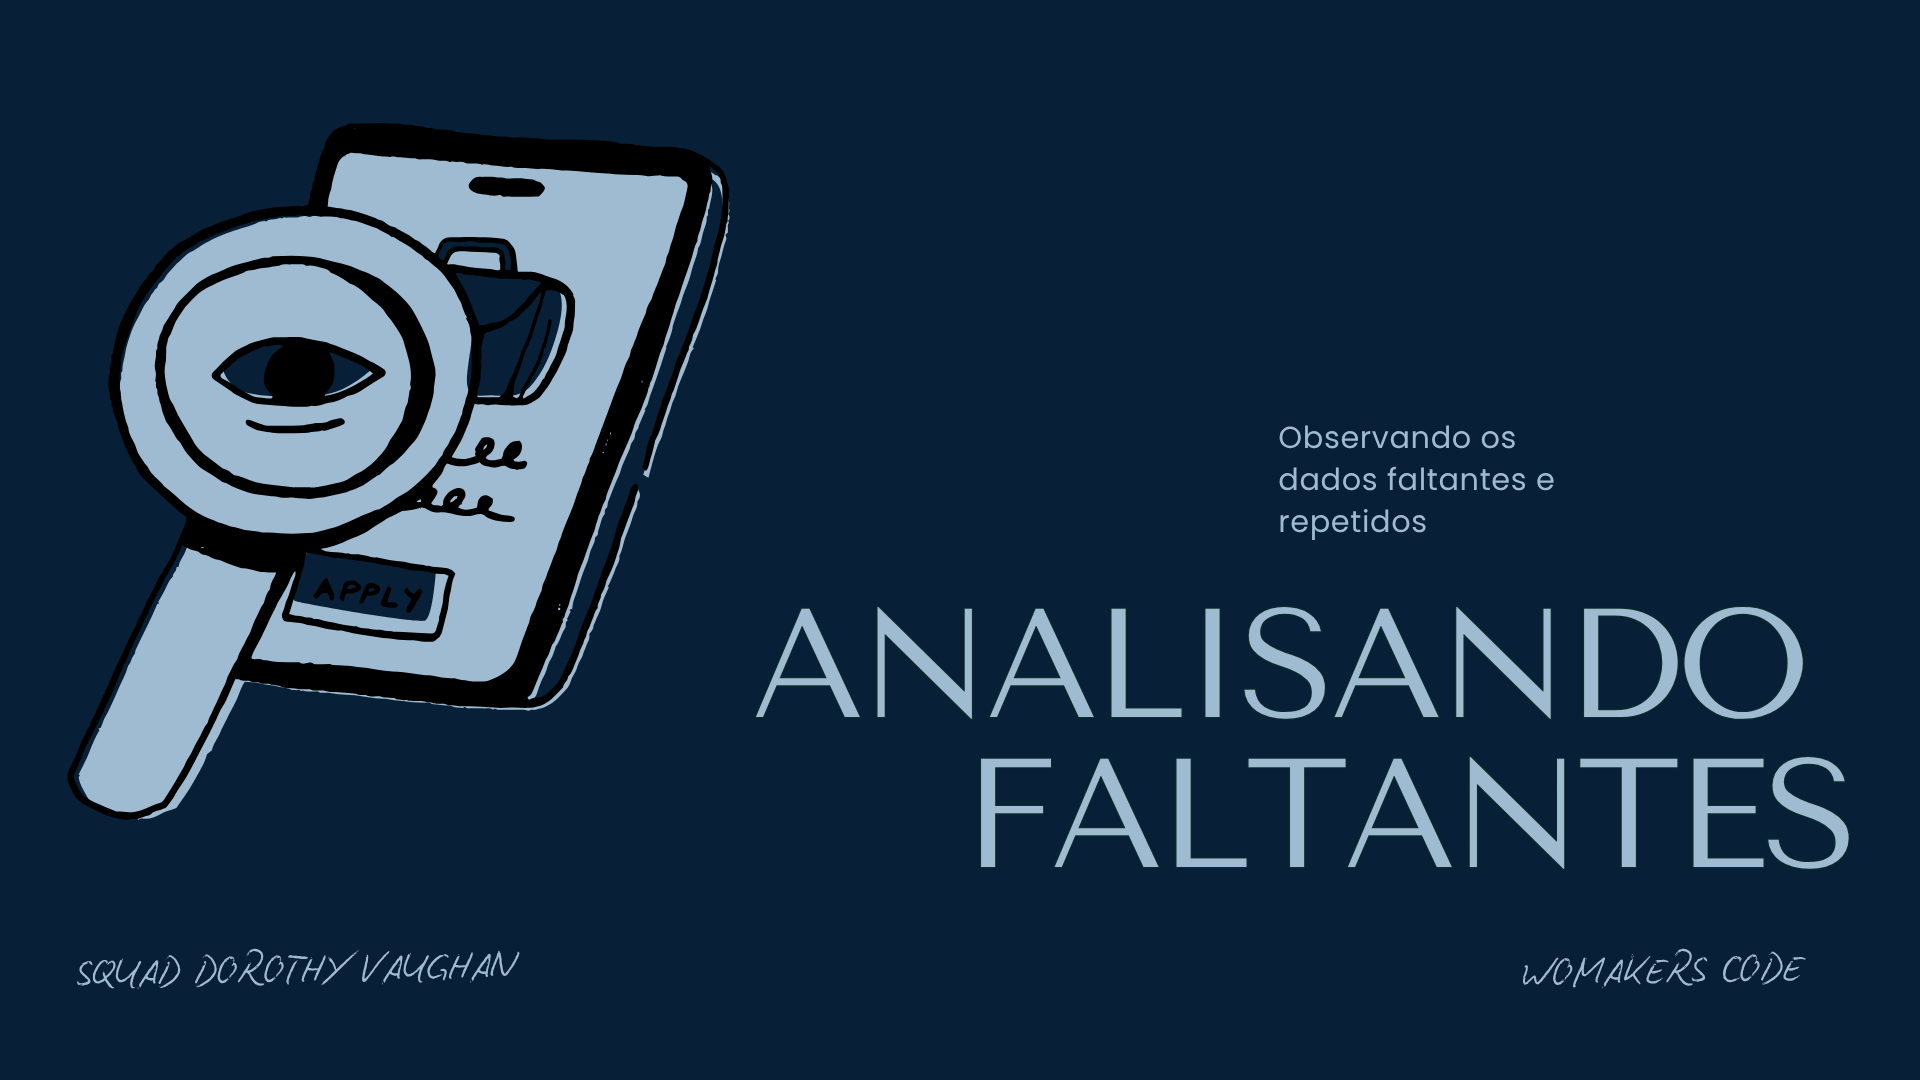

### 1.1 Diagnóstico de qualidade

Análise se tem dado faltando, se algum aluno aparece duas vezes e como as categorias estão distribuídas.

In [ ]:
ausentes = dados.isna().sum()
ausentes = ausentes[ausentes > 0]
percentual = (ausentes / len(dados) * 100).round(1)

print("Valores ausentes:")
print(pd.DataFrame({"quantidade": ausentes, "percentual": percentual}))
print(f"\nIDs duplicados: {dados['student_id'].duplicated().sum()}")

Valores ausentes:
                          quantidade  percentual
parental_education_level          91        9.10

IDs duplicados: 0


In [ ]:
colunas_categoricas = dados.select_dtypes(exclude=np.number).columns.drop("student_id")

for coluna in colunas_categoricas:
    print(f"\n{coluna}")
    print(dados[coluna].value_counts(dropna=False).to_string())


gender
gender
Female    481
Male      477
Other      42

part_time_job
part_time_job
No     785
Yes    215

diet_quality
diet_quality
Fair    437
Good    378
Poor    185

parental_education_level
parental_education_level
High School    392
Bachelor       350
Master         167
NaN             91

internet_quality
internet_quality
Good       447
Average    391
Poor       162

extracurricular_participation
extracurricular_participation
No     682
Yes    318


### 1.2 Tratamento

A coluna `parental_education_level` apresentou 91 registros vazios (9,1% da base). Descartar essas linhas custaria quase 10% da amostra. Optamos por transformar a ausência em categoria própria, `Nao informado`.

Nenhum `student_id` repetido, então não há duplicados. Os tipos vieram todos certos na leitura.

Sobre outliers, decidimos não cortar nada. As notas variam de 18,4 a 100 e qualquer valor nesse intervalo faz sentido para uma prova final.

Uma coisa nos chamou atenção: 48 alunos com nota exatamente 100. A escala trava nesse valor, então quem estaria acima ficou todo empilhado no teto.

In [ ]:
dados_limpos = dados.copy()
dados_limpos["parental_education_level"] = dados_limpos["parental_education_level"].fillna("Nao informado")

rotulos = {
    "study_hours_per_day": "Horas de estudo por dia",
    "social_media_hours": "Horas em redes sociais",
    "netflix_hours": "Horas de Netflix",
    "sleep_hours": "Horas de sono",
    "attendance_percentage": "Frequência às aulas (%)",
    "exercise_frequency": "Exercício (vezes/semana)",
    "mental_health_rating": "Saúde mental (1 a 10)",
    "age": "Idade",
    "exam_score": "Nota final",
}

print("Alunos com nota exatamente 100:", (dados_limpos["exam_score"] == 100).sum())
print("Ausentes restantes:", dados_limpos.isna().sum().sum())

Alunos com nota exatamente 100: 48
Ausentes restantes: 0


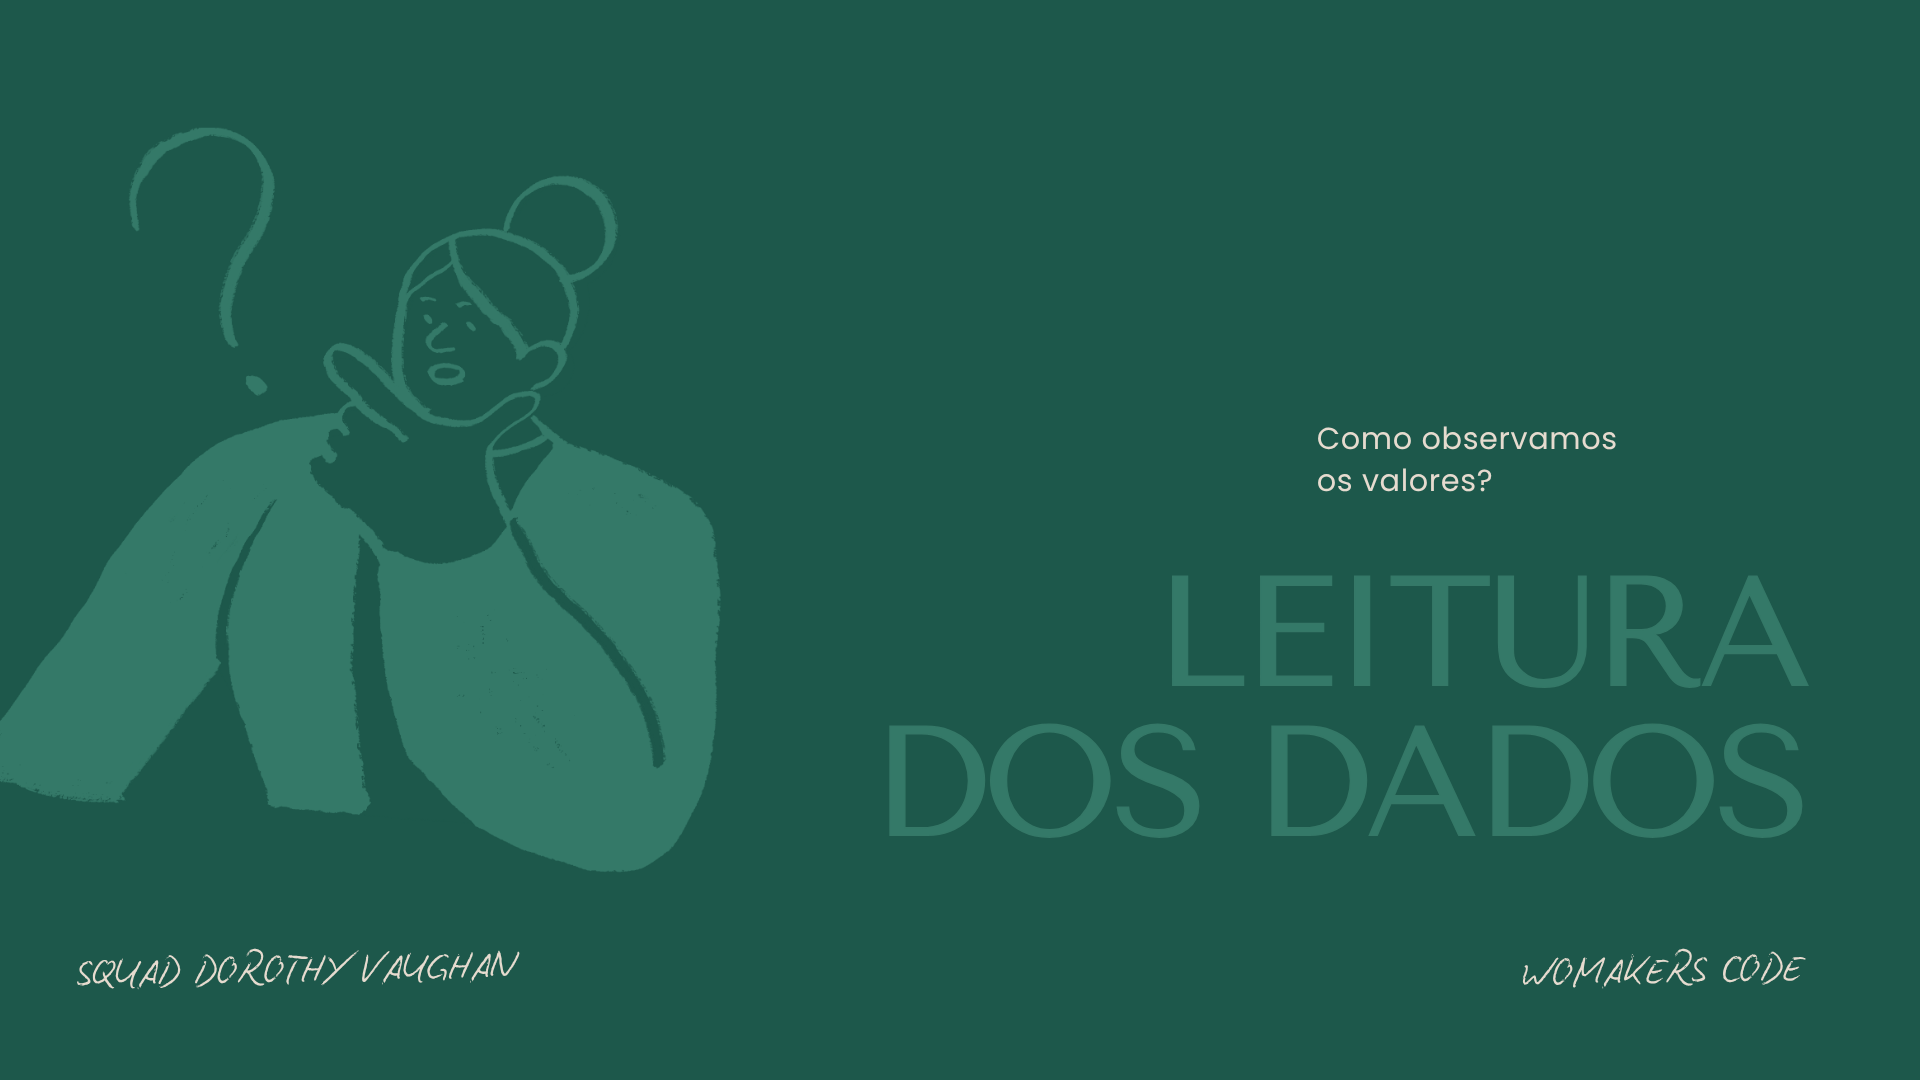

### Como ler os números deste notebook

Para quem for acompanhar a análise sem familiaridade com os termos.

**Correlação (r).** Vai de -1 a 1 e diz se duas coisas andam juntas. Perto de zero é
nenhuma relação. Elevado ao quadrado, vira a porcentagem da variação que uma
acompanha na outra. Andar junto não é causar.

**p-valor.** A chance de o que você viu ter aparecido por acaso, num cenário onde
não existe diferença de verdade. Abaixo de 0,05 a gente aceita como real. p alto não
prova que os grupos são iguais, só diz que não dá para afirmar que são diferentes.

**Coeficiente.** Quanto a nota muda quando a variável sobe uma unidade, mantendo
todo o resto parado. É essa última parte que diferencia a regressão da correlação.

**R².** Quanto da variação das notas o modelo consegue explicar, de 0 a 1.

**MAE e RMSE.** Erro médio do modelo em pontos de nota. O RMSE pune erro grande
com mais força, então quando os dois ficam parecidos é porque não há aluno com
erro absurdo distorcendo a conta.

**Treino e teste.** O modelo aprende com 800 alunos e é avaliado em 200 que nunca
viu. Desempenho bom no treino e ruim no teste significa que ele decorou.

**Resíduo.** A diferença entre a nota real e a prevista, aluno por aluno.

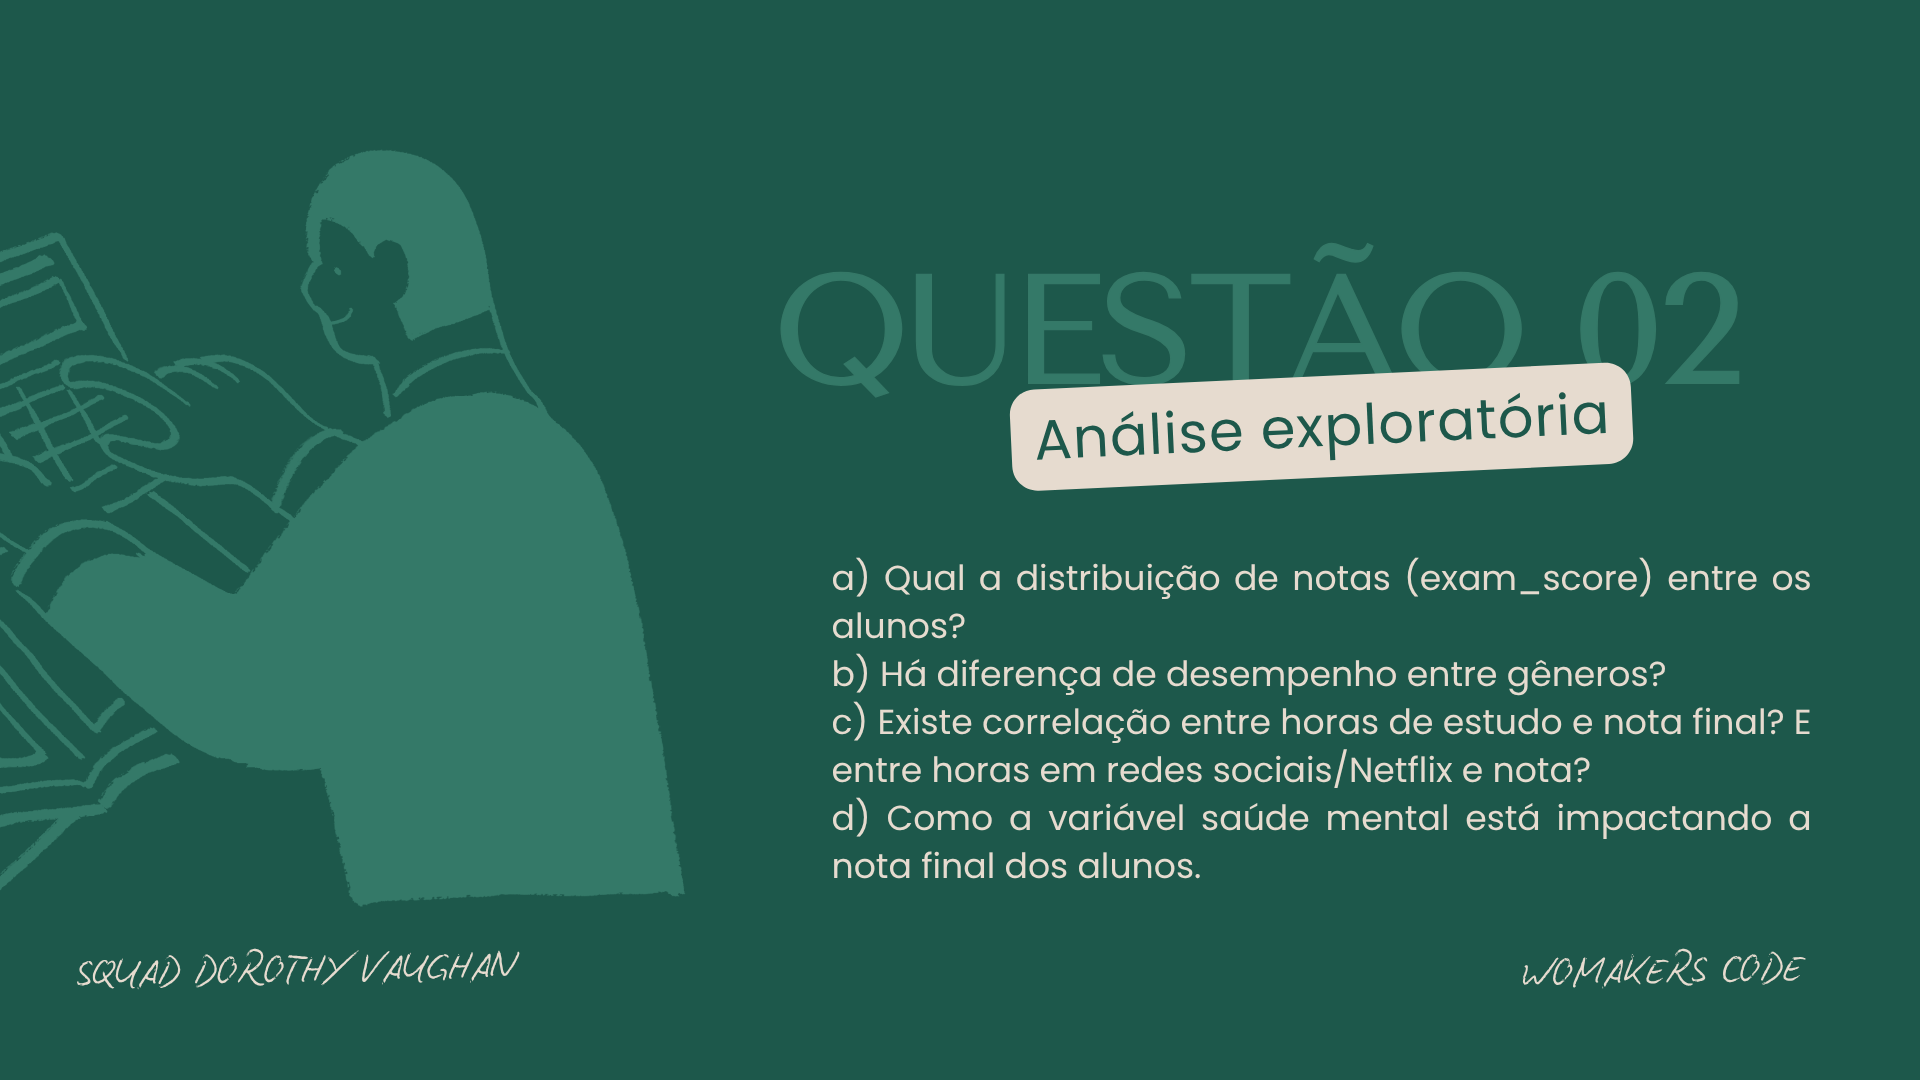

## 2. Análise exploratória dos dados

### 2.1 Como as notas se distribuem?

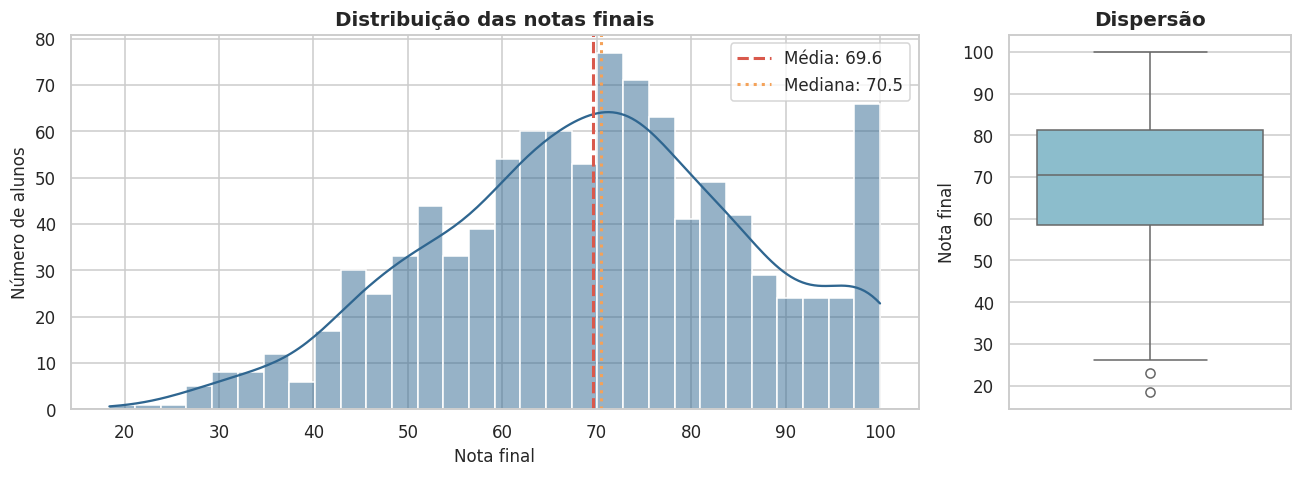

count   1,000.00
mean       69.60
std        16.89
min        18.40
25%        58.48
50%        70.50
75%        81.33
max       100.00

Assimetria: -0.156


In [ ]:
figura, eixos = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [3, 1]})

sns.histplot(dados_limpos["exam_score"], bins=30, kde=True, color=AZUL, ax=eixos[0])
eixos[0].axvline(dados_limpos["exam_score"].mean(), color=VERMELHO, linestyle="--", linewidth=2,
                 label=f"Média: {dados_limpos['exam_score'].mean():.1f}")
eixos[0].axvline(dados_limpos["exam_score"].median(), color=LARANJA, linestyle=":", linewidth=2,
                 label=f"Mediana: {dados_limpos['exam_score'].median():.1f}")
eixos[0].set_title("Distribuição das notas finais")
eixos[0].set_xlabel("Nota final")
eixos[0].set_ylabel("Número de alunos")
eixos[0].legend()

sns.boxplot(y=dados_limpos["exam_score"], color=AZUL_CLARO, ax=eixos[1])
eixos[1].set_title("Dispersão")
eixos[1].set_ylabel("Nota final")

plt.tight_layout()
plt.show()

print(dados_limpos["exam_score"].describe().to_string())
print(f"\nAssimetria: {dados_limpos['exam_score'].skew():.3f}")

A distribuição ficou simétrica, com média 69,6, mediana 70,5 e assimetria de -0,156.

O que pesa mesmo é o desvio padrão de 16,89. Do primeiro para o terceiro quartil dá mais de 22 pontos de diferença, ou seja, a turma é bem desigual.

E aparece de novo a barra na ponta direita. Aqueles 48 alunos com 100.

### 2.2 Há diferença de desempenho entre gêneros?

In [ ]:
resumo_genero = (dados_limpos.groupby("gender")["exam_score"]
                 .agg(alunos="count", media="mean", mediana="median", desvio="std")
                 .round(2))
print(resumo_genero.to_string())

grupos = [grupo["exam_score"].values for _, grupo in dados_limpos.groupby("gender")]
estatistica_f, valor_p = stats.f_oneway(*grupos)
print(f"\nANOVA: F = {estatistica_f:.3f} | p = {valor_p:.4f}")

estatistica_kw, valor_p_kw = stats.kruskal(*grupos)
print(f"Kruskal-Wallis: H = {estatistica_kw:.3f} | p = {valor_p_kw:.4f}")

        alunos  media  mediana  desvio
gender                                
Female     481  69.74    70.70   16.90
Male       477  69.37    70.20   17.15
Other       42  70.65    69.00   13.76

ANOVA: F = 0.142 | p = 0.8674
Kruskal-Wallis: H = 0.150 | p = 0.9277


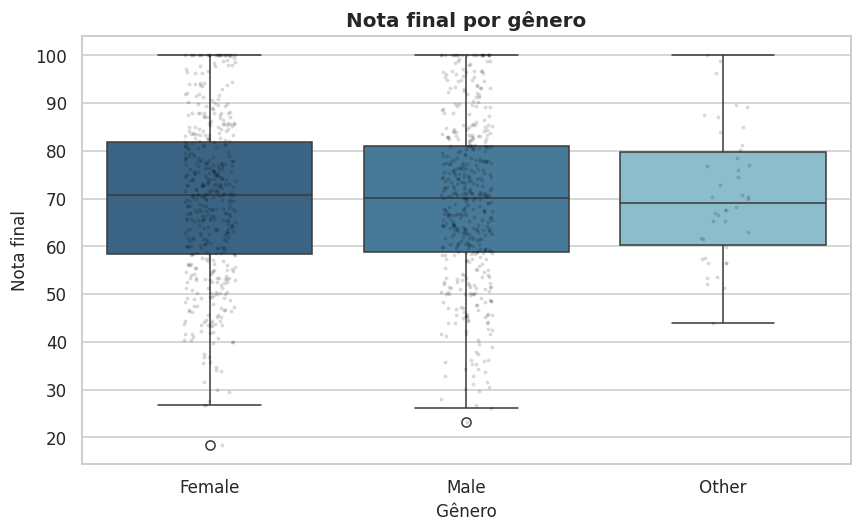

In [ ]:
figura, eixo = plt.subplots(figsize=(8, 5))

sns.boxplot(data=dados_limpos, x="gender", y="exam_score", hue="gender",
            palette=PALETA[:3], legend=False, ax=eixo)
sns.stripplot(data=dados_limpos, x="gender", y="exam_score",
              color="black", alpha=0.15, size=2.5, ax=eixo)

eixo.set_title("Nota final por gênero")
eixo.set_xlabel("Gênero")
eixo.set_ylabel("Nota final")
plt.tight_layout()
plt.show()

Nenhuma. As médias deram 69,7 (Female), 69,37 (Male) e 70,65 (Other), e a ANOVA veio com p = 0,87. A diferença de 1,3 ponto entre o maior e o menor grupo é ruído, ainda mais com só 42 alunos no grupo Other.


### 2.3 Estudo, redes sociais e Netflix têm relação com a nota?

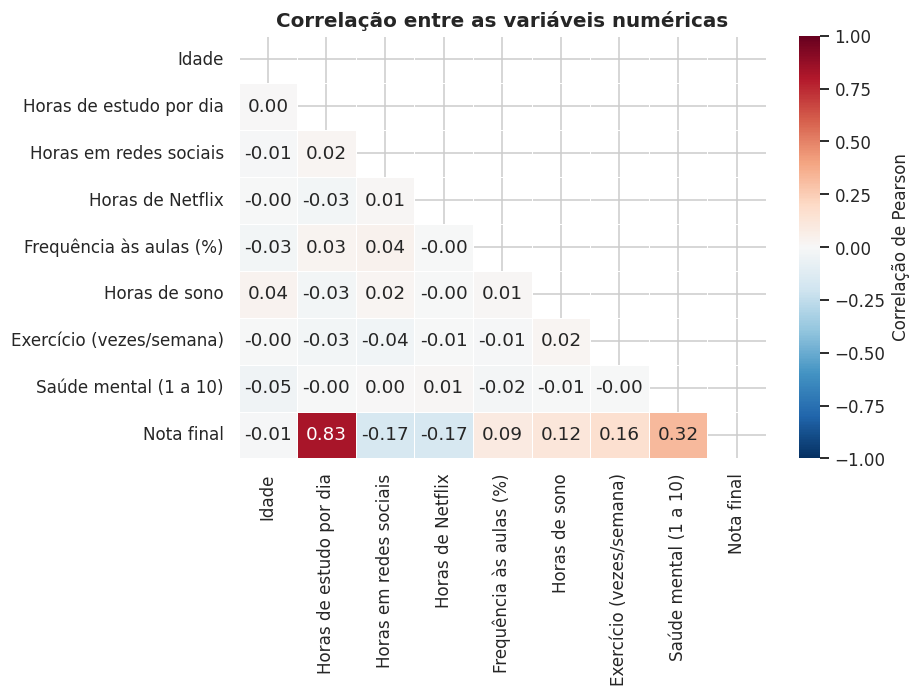

In [ ]:
colunas_numericas = dados_limpos.select_dtypes(include=np.number).columns
matriz_correlacao = dados_limpos[colunas_numericas].corr()

figura, eixo = plt.subplots(figsize=(8.5, 6.5))
mascara = np.triu(np.ones_like(matriz_correlacao, dtype=bool))

sns.heatmap(matriz_correlacao.rename(index=rotulos, columns=rotulos),
            mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=eixo,
            cbar_kws={"label": "Correlação de Pearson"})

eixo.set_title("Correlação entre as variáveis numéricas")
plt.tight_layout()
plt.show()

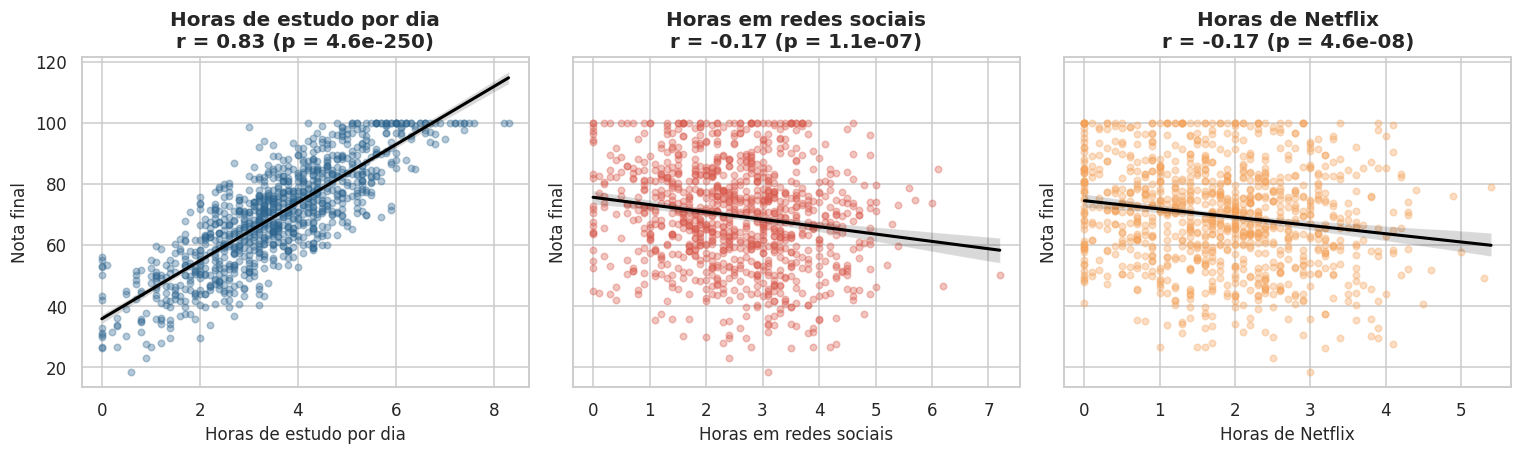

In [ ]:
variaveis_foco = ["study_hours_per_day", "social_media_hours", "netflix_hours"]
cores_foco = [AZUL, VERMELHO, LARANJA]

figura, eixos = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)

for eixo, coluna, cor in zip(eixos, variaveis_foco, cores_foco):
    coeficiente, valor_p = stats.pearsonr(dados_limpos[coluna], dados_limpos["exam_score"])
    sns.regplot(data=dados_limpos, x=coluna, y="exam_score", ax=eixo,
                scatter_kws={"alpha": 0.35, "s": 18, "color": cor},
                line_kws={"color": "black", "linewidth": 2})
    eixo.set_title(f"{rotulos[coluna]}\nr = {coeficiente:.2f} (p = {valor_p:.1e})")
    eixo.set_xlabel(rotulos[coluna])
    eixo.set_ylabel("Nota final")

plt.tight_layout()
plt.show()

In [ ]:
# Efeito prático: compara o quarto de alunos que menos faz cada atividade com o
# quarto que mais faz.
linhas = []

for coluna in variaveis_foco:
    primeiro_quartil = dados_limpos[coluna].quantile(0.25)
    terceiro_quartil = dados_limpos[coluna].quantile(0.75)
    media_quarto_baixo = dados_limpos[dados_limpos[coluna] <= primeiro_quartil]["exam_score"].mean()
    media_quarto_alto = dados_limpos[dados_limpos[coluna] >= terceiro_quartil]["exam_score"].mean()
    correlacao, _ = stats.pearsonr(dados_limpos[coluna], dados_limpos["exam_score"])

    linhas.append({
        "Variável": rotulos[coluna],
        "Corte do 1º quartil": primeiro_quartil,
        "Nota do quarto que menos faz": media_quarto_baixo,
        "Corte do 3º quartil": terceiro_quartil,
        "Nota do quarto que mais faz": media_quarto_alto,
        "Diferença em pontos": media_quarto_alto - media_quarto_baixo,
        "Variação acompanhada (%)": correlacao ** 2 * 100,
    })

efeito_pratico = pd.DataFrame(linhas).set_index("Variável")
print(efeito_pratico.to_string(float_format=lambda valor: f"{valor:.1f}"))

# Redes sociais e Netflix disputam o mesmo espaço no dia, então faz sentido
# olhar as duas somadas como tempo total de tela.
dados_limpos["tempo_de_tela"] = dados_limpos["social_media_hours"] + dados_limpos["netflix_hours"]
correlacao_tela, p_tela = stats.pearsonr(dados_limpos["tempo_de_tela"], dados_limpos["exam_score"])

print(f"\nTempo total de tela (redes + Netflix)")
print(f"Média da turma: {dados_limpos['tempo_de_tela'].mean():.1f} horas por dia")
print(f"r = {correlacao_tela:.3f} (p = {p_tela:.2e}), acompanha {correlacao_tela ** 2 * 100:.1f}% da variação")

                         Corte do 1º quartil  Nota do quarto que menos faz  Corte do 3º quartil  Nota do quarto que mais faz  Diferença em pontos  Variação acompanhada (%)
Variável                                                                                                                                                                   
Horas de estudo por dia                  2.6                          52.3                  4.5                         86.8                 34.5                      68.1
Horas em redes sociais                   1.7                          73.0                  3.3                         66.1                 -6.9                       2.8
Horas de Netflix                         1.0                          73.7                  2.5                         66.5                 -7.2                       3.0

Tempo total de tela (redes + Netflix)
Média da turma: 4.3 horas por dia
r = -0.238 (p = 2.65e-14), acompanha 5.6% da variação


Existe correlação nos três casos, mas com forças muito diferentes.

**Horas de estudo: sim, e é a relação mais forte da base.** O r deu 0,83, com p praticamente zero. Elevando ao quadrado, chegamos a 68%, ou seja, horas de estudo sozinha acompanha mais de dois terços da variação das notas. Na dispersão os pontos ficam apertados em volta da reta, o que mostra que não é efeito de uns poucos alunos puxando o resultado. Em termos práticos: o quarto que menos estuda, até 2,6 horas por dia, tira 52,3 de média, enquanto o quarto que mais estuda, acima de 4,5 horas, tira 86,8. São 34,5 pontos de diferença.

**Redes sociais: sim, negativa e fraca.** O r deu -0,17, então quanto mais tempo em redes, menor a nota. O p de 0,0000001 confirma que a relação existe e não é acaso, só que ela acompanha apenas 2,8% da variação. Comparando os quartos extremos, quem passa até 1,7 hora por dia tira 73,0 e quem passa mais de 3,3 horas tira 66,1, uma diferença de 6,9 pontos.

**Netflix: praticamente igual às redes sociais.** O r deu -0,17 e acompanha 3,0% da variação. Entre os quartos extremos a diferença é de 7,2 pontos.

Aqui cabe uma distinção que consideramos importante. Significância estatística e tamanho do efeito são coisas diferentes. Redes sociais e Netflix passam com folga no teste de significância, então a relação é real. Mas cada uma explica menos de 3% da variação, contra 68% das horas de estudo. Dizer que redes sociais derrubam o desempenho dos alunos seria esticar muito além do que o dado sustenta.

Também investigamos se o lazer digital estaria roubando hora de estudo, que seria o caminho indireto mais provável. Não está. No mapa de calor, a correlação entre horas de estudo e redes sociais é de 0,02 e com Netflix é de -0,03, as duas coladas em zero. Quem passa mais tempo em tela não estuda menos, então o efeito das duas é pequeno e direto.

Por último, somamos redes sociais e Netflix num único indicador de tempo de tela, já que disputam o mesmo espaço no dia. Juntas chegam a r = -0,24 e acompanham 5,6% da variação, com média de 4,3 horas diárias na turma. É mais do que cada uma separada, mas continua longe do peso das horas de estudo.

### 2.4 Qual o impacto da saúde mental na nota?

In [ ]:
dados_limpos["faixa_saude_mental"] = pd.cut(
    dados_limpos["mental_health_rating"],
    bins=[0, 3, 6, 10],
    labels=["Baixa (1-3)", "Média (4-6)", "Alta (7-10)"]
)

resumo_saude = (dados_limpos.groupby("faixa_saude_mental", observed=True)["exam_score"]
                .agg(alunos="count", media="mean", desvio="std")
                .round(2))
print(resumo_saude.to_string())

coeficiente, valor_p = stats.pearsonr(dados_limpos["mental_health_rating"], dados_limpos["exam_score"])
print(f"\nCorrelação com a nota: r = {coeficiente:.3f} (p = {valor_p:.2e})")

                    alunos  media  desvio
faixa_saude_mental                       
Baixa (1-3)            301  63.43   15.94
Média (4-6)            317  67.87   16.85
Alta (7-10)            382  75.90   15.49

Correlação com a nota: r = 0.322 (p = 1.75e-25)


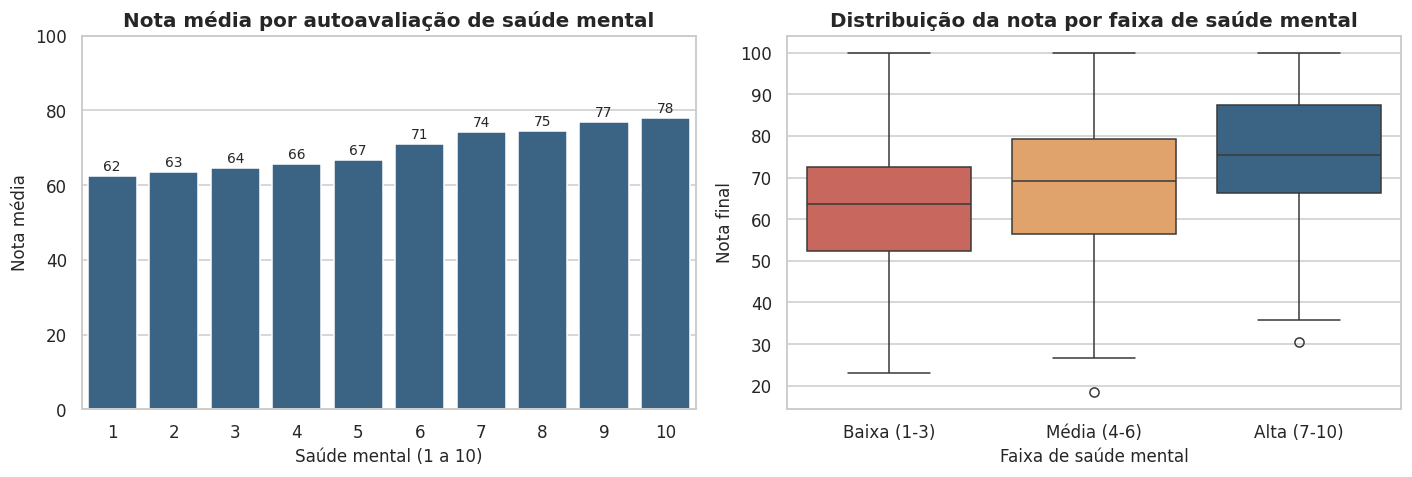

In [ ]:
figura, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

media_por_nota = dados_limpos.groupby("mental_health_rating")["exam_score"].mean()
sns.barplot(x=media_por_nota.index, y=media_por_nota.values, color=AZUL, ax=eixos[0])
eixos[0].set_title("Nota média por autoavaliação de saúde mental")
eixos[0].set_xlabel("Saúde mental (1 a 10)")
eixos[0].set_ylabel("Nota média")
eixos[0].set_ylim(0, 100)

for indice, valor in enumerate(media_por_nota.values):
    eixos[0].text(indice, valor + 1.5, f"{valor:.0f}", ha="center", fontsize=9)

sns.boxplot(data=dados_limpos, x="faixa_saude_mental", y="exam_score",
            hue="faixa_saude_mental", palette=[VERMELHO, LARANJA, AZUL],
            legend=False, ax=eixos[1])
eixos[1].set_title("Distribuição da nota por faixa de saúde mental")
eixos[1].set_xlabel("Faixa de saúde mental")
eixos[1].set_ylabel("Nota final")

plt.tight_layout()
plt.show()

Saúde mental ficou em segundo lugar, com r = 0,32, e o comportamento é bem regular: a nota média sobe quase degrau a degrau da autoavaliação 1 até a 10.

Quem se avalia mal tira 63,4 em média, quem se avalia bem tira 75,9. São 12,5 pontos de distância, e o grupo da faixa baixa reúne 301 alunos, quase um terço da turma.

Uma ressalva: a base é transversal, uma foto de um momento só. Não dá para saber o que vem antes. Estar mal pode atrapalhar o estudo, e ir mal na prova também derruba o astral. Nossa leitura é que as duas coisas se complementam.



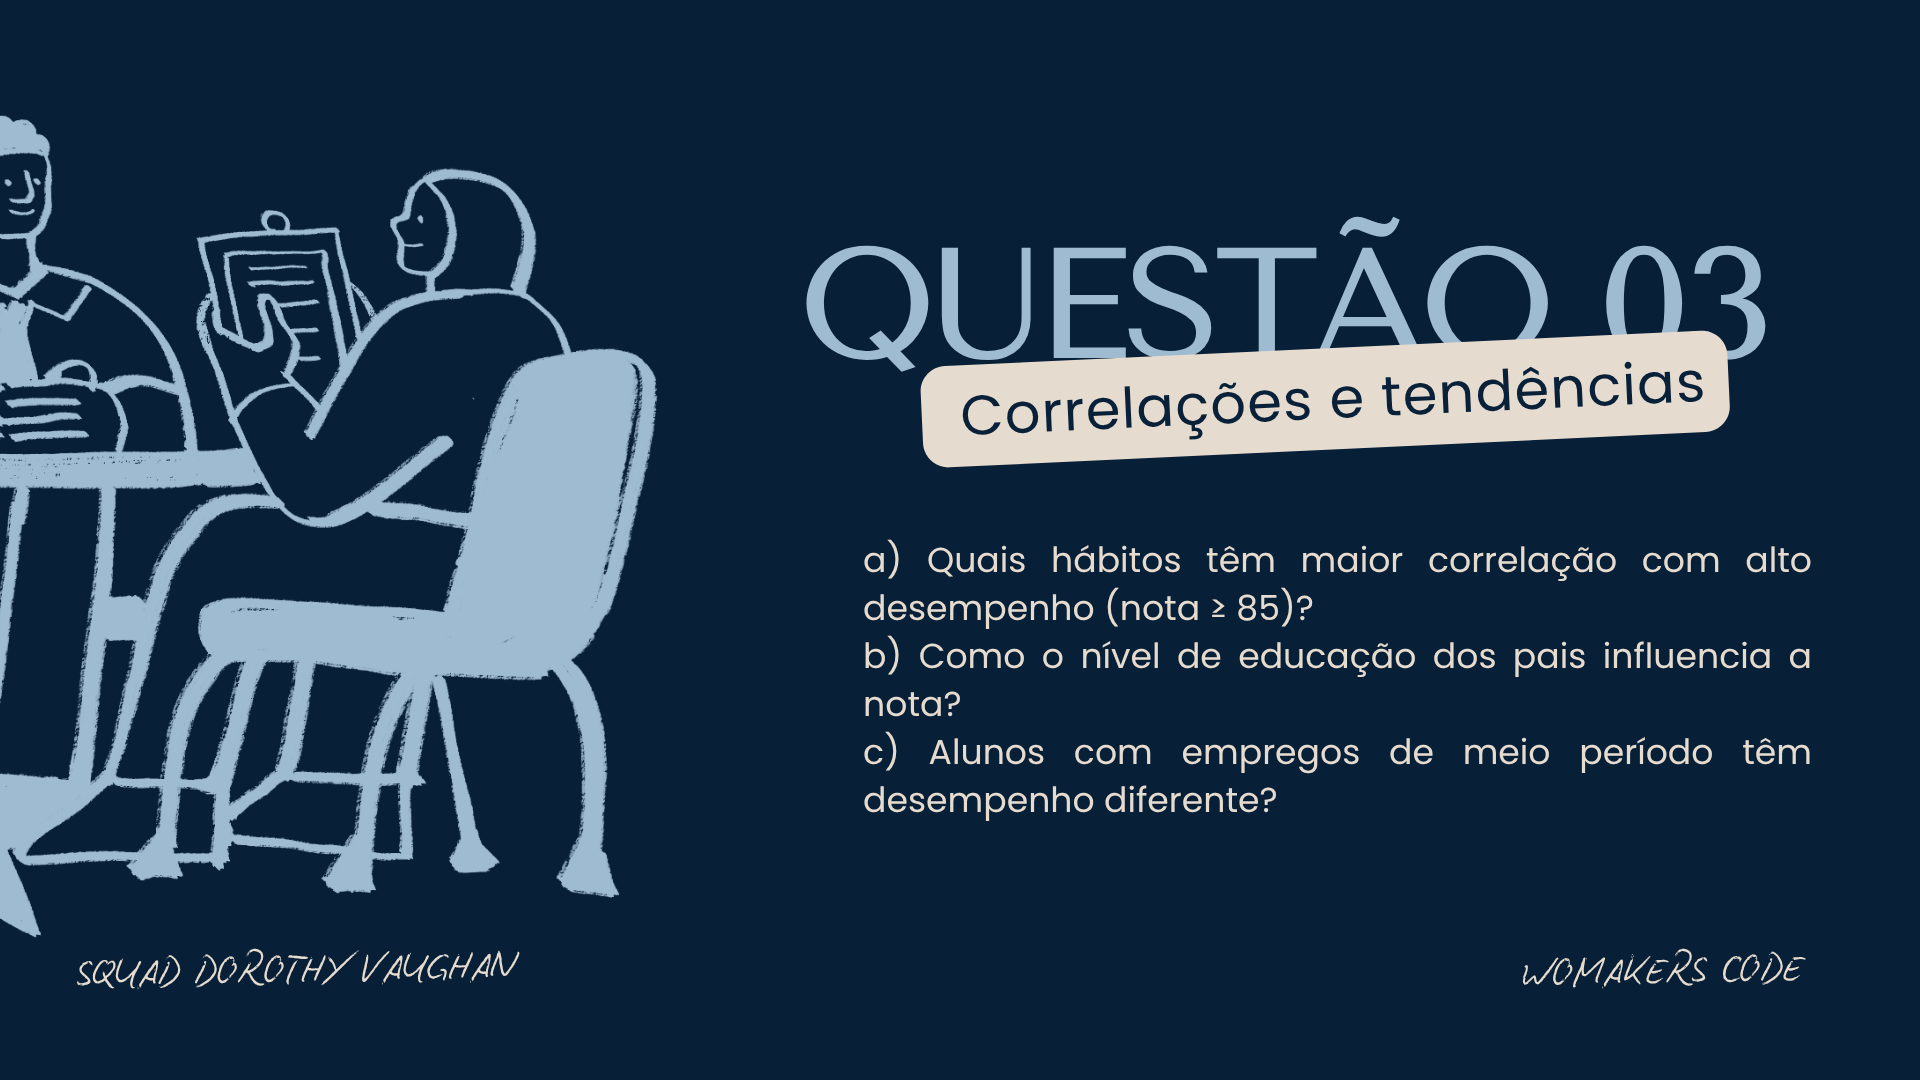

## 3. Correlações e tendências

### 3.1 Quais hábitos têm maior correlação com alto desempenho (nota >= 85)?

In [ ]:
# 1. Criação do indicador binário de alto desempenho (1 = sim, 0 = não)
dados_limpos["alto_desempenho"] = (dados_limpos["exam_score"] >= 85).astype(int)
dados_limpos["grupo_desempenho"] = np.where(dados_limpos["alto_desempenho"] == 1, "Nota >= 85", "Nota < 85")

print("Distribuição dos grupos:")
print(dados_limpos["grupo_desempenho"].value_counts().to_string())

habitos = ["study_hours_per_day", "mental_health_rating", "exercise_frequency",
           "sleep_hours", "attendance_percentage", "social_media_hours", "netflix_hours"]

# 2. Cálculo das médias, diferença e correlação ponto-bisserial
linhas_comparacao = []
for h in habitos:
    media_alto = dados_limpos[dados_limpos["alto_desempenho"] == 1][h].mean()
    media_baixo = dados_limpos[dados_limpos["alto_desempenho"] == 0][h].mean()
    r_pb, p_pb = stats.pointbiserialr(dados_limpos["alto_desempenho"], dados_limpos[h])
    r_cont, _ = stats.pearsonr(dados_limpos["exam_score"], dados_limpos[h])

    linhas_comparacao.append({
        "Hábito": rotulos[h],
        "Média (>= 85)": media_alto,
        "Média (< 85)": media_baixo,
        "Diferença": media_alto - media_baixo,
        "Corr. Alto Desempenho (r_pb)": r_pb,
        "p-valor": p_pb,
        "Corr. Nota Contínua": r_cont
    })

comparacao = pd.DataFrame(linhas_comparacao).set_index("Hábito")
comparacao = comparacao.sort_values("Corr. Alto Desempenho (r_pb)", ascending=False)
comparacao.round(3)

Distribuição dos grupos:
grupo_desempenho
Nota < 85     812
Nota >= 85    188


,Média (>= 85),Média (< 85),Diferença,Corr. Alto Desempenho (r_pb),p-valor,Corr. Nota Contínua
Hábito,,,,,,
Horas de estudo por dia,5.32,3.14,2.18,0.58,0.00,0.82
Saúde mental (1 a 10),6.83,5.12,1.72,0.24,0.00,0.32
Exercício (vezes/semana),3.58,2.92,0.66,0.13,0.00,0.16
Horas de sono,6.70,6.42,0.29,0.09,0.00,0.12
Frequência às aulas (%),85.83,83.74,2.10,0.09,0.01,0.09
Horas de Netflix,1.61,1.87,-0.26,-0.10,0.00,-0.17
Horas em redes sociais,2.26,2.56,-0.30,-0.10,0.00,-0.17


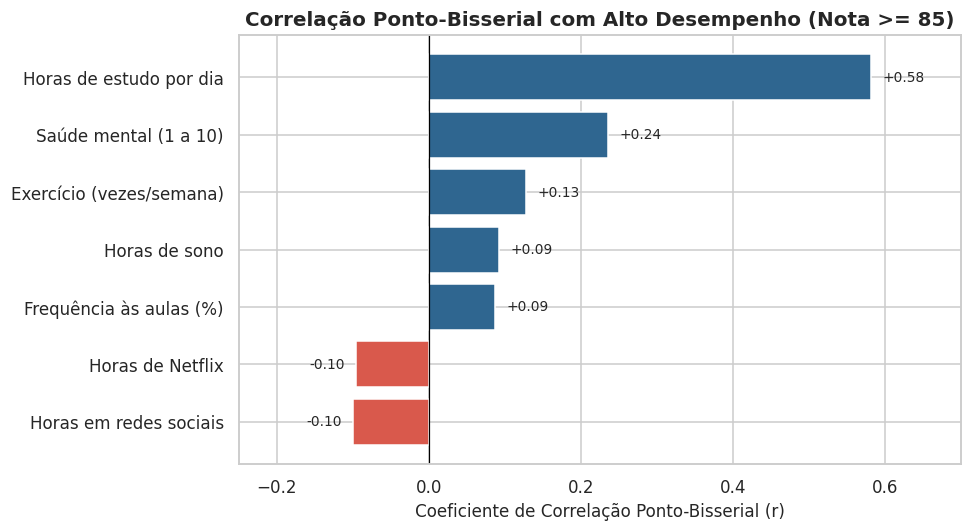

In [ ]:
correlacoes_pb = comparacao["Corr. Alto Desempenho (r_pb)"].sort_values()
cores = [VERMELHO if valor < 0 else AZUL for valor in correlacoes_pb]

figura, eixo = plt.subplots(figsize=(9, 5))
barras = eixo.barh(correlacoes_pb.index, correlacoes_pb.values, color=cores)
eixo.axvline(0, color="black", linewidth=0.8)
eixo.set_title("Correlação Ponto-Bisserial com Alto Desempenho (Nota >= 85)")
eixo.set_xlabel("Coeficiente de Correlação Ponto-Bisserial (r)")
eixo.set_xlim(-0.25, 0.70)

for barra, valor in zip(barras, correlacoes_pb.values):
    deslocamento = 0.015 if valor >= 0 else -0.015
    eixo.text(valor + deslocamento, barra.get_y() + barra.get_height() / 2,
              f"{valor:+.2f}", va="center",
              ha="left" if valor >= 0 else "right", fontsize=9)

plt.tight_layout()
plt.show()

Horas de estudo é o hábito que têm maior correlação com alto desempenho, com r = 0,58, seguido de saúde mental com 0,24.

Redes sociais e Netflix são os únicos negativos.O grupo de alto desempenho passa cerca de 20 minutos a menos por dia em cada uma das duas.

No gráfico de barras essa desproporção fica evidente. A barra de horas de estudo é mais que o dobro da segunda colocada e cerca de cinco vezes maior que todas as demais juntas em termos de distância do zero.

O aluno de alto desempenho estuda substancialmente mais e está melhor psicologicamente. Os outros cinco hábitos separam pouco, e nenhuma variável de contexto social aparece.


### 3.2 A escolaridade dos pais influencia a nota?

In [ ]:
ordem_escolaridade = ["High School", "Bachelor", "Master", "Nao informado"]

resumo_pais = (dados_limpos.groupby("parental_education_level")["exam_score"]
               .agg(alunos="count", media="mean", desvio="std")
               .reindex(ordem_escolaridade)
               .round(2))
print(resumo_pais.to_string())

com_informacao = dados_limpos[dados_limpos["parental_education_level"] != "Nao informado"]
grupos_pais = [grupo["exam_score"].values for _, grupo in com_informacao.groupby("parental_education_level")]
estatistica_f, valor_p = stats.f_oneway(*grupos_pais)
print(f"\nANOVA (sem os não informados): F = {estatistica_f:.3f} | p = {valor_p:.4f}")

estatistica_kw, valor_p_kw = stats.kruskal(*grupos_pais)
print(f"Kruskal-Wallis: H = {estatistica_kw:.3f} | p = {valor_p_kw:.4f}")

                          alunos  media  desvio
parental_education_level                       
High School                  392  69.55   16.83
Bachelor                     350  70.27   17.29
Master                       167  68.09   16.40
Nao informado                 91  70.03   16.56

ANOVA (sem os não informados): F = 0.942 | p = 0.3901
Kruskal-Wallis: H = 2.991 | p = 0.2241


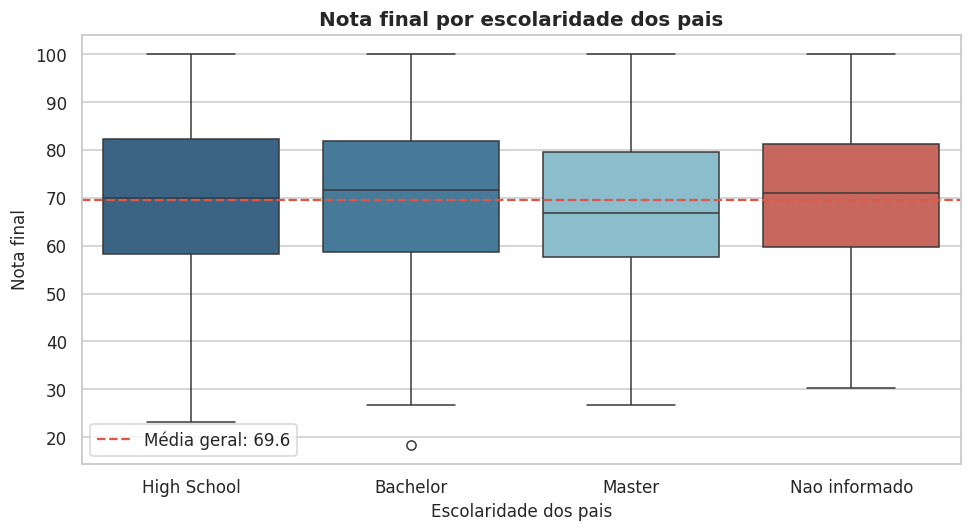

In [ ]:
figura, eixo = plt.subplots(figsize=(9, 5))

sns.boxplot(data=dados_limpos, x="parental_education_level", y="exam_score",
            order=ordem_escolaridade, hue="parental_education_level",
            hue_order=ordem_escolaridade, palette=PALETA[:4], legend=False, ax=eixo)
eixo.axhline(dados_limpos["exam_score"].mean(), color=VERMELHO, linestyle="--",
             linewidth=1.5, label=f"Média geral: {dados_limpos['exam_score'].mean():.1f}")

eixo.set_title("Nota final por escolaridade dos pais")
eixo.set_xlabel("Escolaridade dos pais")
eixo.set_ylabel("Nota final")
eixo.legend()
plt.tight_layout()
plt.show()

Não influencia. As médias ficam entre 68,09 e 70,27 e nem seguem uma ordem lógica, porque os filhos de pais com mestrado tiraram a menor média das três categorias. A ANOVA deu p = 0,39.

O grupo `Nao informado` ficou com média 70,03, perto da média geral.

### 3.3 Alunos com emprego de meio período têm desempenho diferente?

In [ ]:
com_emprego = dados_limpos[dados_limpos["part_time_job"] == "Yes"]["exam_score"]
sem_emprego = dados_limpos[dados_limpos["part_time_job"] == "No"]["exam_score"]

estatistica_t, valor_p = stats.ttest_ind(com_emprego, sem_emprego, equal_var=False)

print(f"Com emprego  (n = {len(com_emprego)}): média {com_emprego.mean():.2f}")
print(f"Sem emprego  (n = {len(sem_emprego)}): média {sem_emprego.mean():.2f}")
print(f"Diferença: {com_emprego.mean() - sem_emprego.mean():.2f} ponto")
print(f"\nTeste t: t = {estatistica_t:.3f} | p = {valor_p:.4f}")

estatistica_u, valor_p_u = stats.mannwhitneyu(com_emprego, sem_emprego)
print(f"Mann-Whitney U: U = {estatistica_u:.1f} | p = {valor_p_u:.4f}")

Com emprego  (n = 215): média 68.74
Sem emprego  (n = 785): média 69.84
Diferença: -1.09 ponto

Teste t: t = -0.852 | p = 0.3946
Mann-Whitney U: U = 80788.5 | p = 0.3375


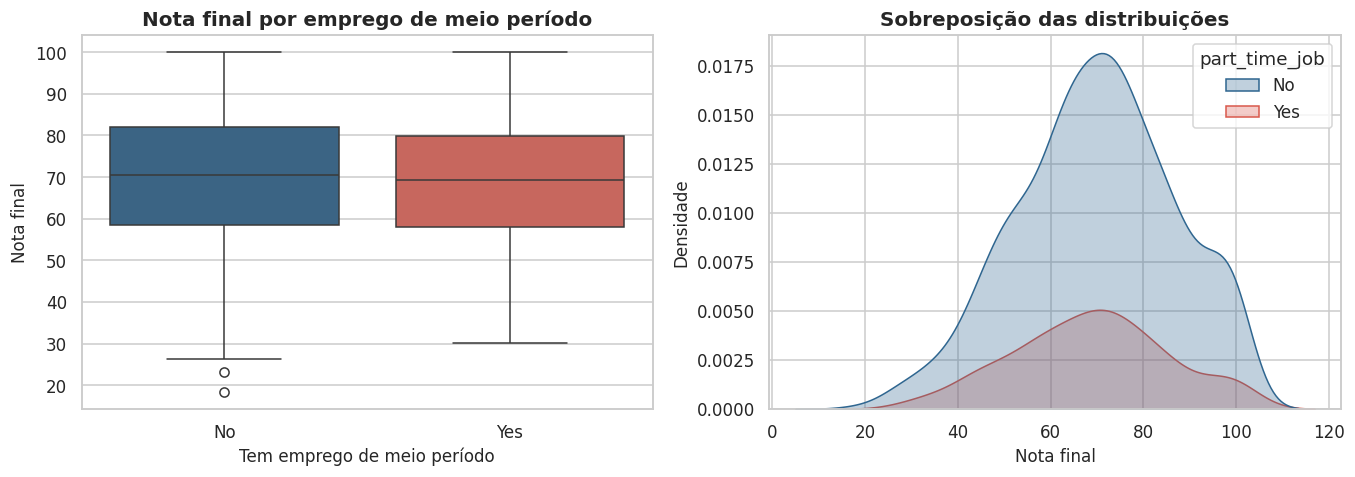

In [ ]:
figura, eixos = plt.subplots(1, 2, figsize=(12.5, 4.5))

sns.boxplot(data=dados_limpos, x="part_time_job", y="exam_score", hue="part_time_job",
            palette=[AZUL, VERMELHO], legend=False, ax=eixos[0])
eixos[0].set_title("Nota final por emprego de meio período")
eixos[0].set_xlabel("Tem emprego de meio período")
eixos[0].set_ylabel("Nota final")

sns.kdeplot(data=dados_limpos, x="exam_score", hue="part_time_job",
            fill=True, alpha=0.3, palette=[AZUL, VERMELHO], ax=eixos[1])
eixos[1].set_title("Sobreposição das distribuições")
eixos[1].set_xlabel("Nota final")
eixos[1].set_ylabel("Densidade")

plt.tight_layout()
plt.show()

Diferença de 1,1 ponto a favor de quem não trabalha, com p = 0,39. Na prática é zero: no gráfico de densidade as duas curvas se sobrepõem quase inteiras.

A amostra é desbalanceada, 215 alunos empregados contra 785. Mesmo assim, 215 observações bastariam para o teste pegar um efeito relevante, se ele existisse. Para nós, trabalhar meio período não está associado a nota pior nesta base.

### Onde chegamos antes de modelar

| Pergunta | Resposta |
|---|---|
| Distribuição das notas | Simétrica, média 69,6, alta dispersão, teto artificial em 100 |
| Gênero | Sem diferença (p = 0,87) |
| Horas de estudo | Correlação forte, r = 0,83 |
| Redes sociais e Netflix | Correlação negativa fraca, r = -0,17 cada |
| Saúde mental | Segunda maior associação, r = 0,32 |
| Escolaridade dos pais | Sem efeito (p = 0,39) |
| Emprego meio período | Sem efeito (p = 0,39) |

O sinal está concentrado em quatro variáveis: estudo, saúde mental, lazer digital e, num grau bem menor, sono e exercício. As de contexto social não separam nada. O modelo da próxima seção testa tudo junto e diz se esse quadro se sustenta quando as variáveis competem entre si.

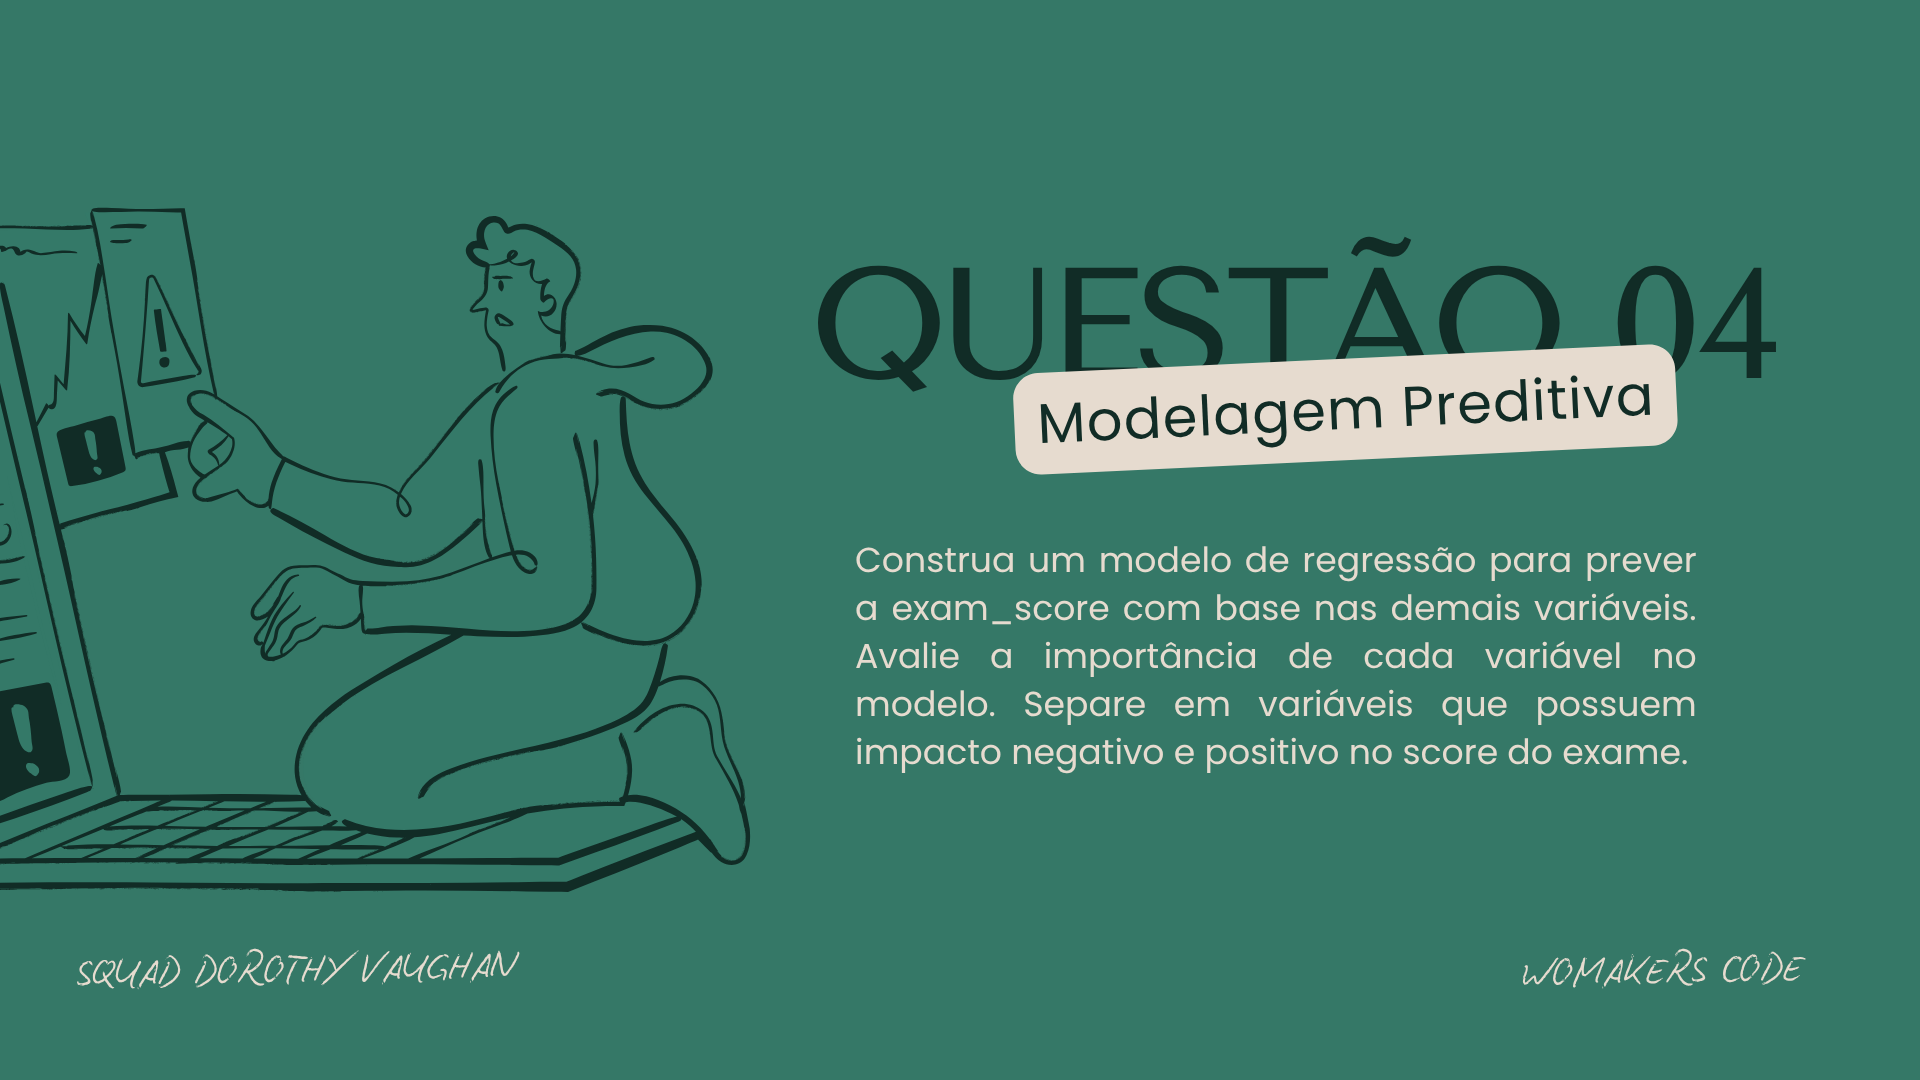

## 4. Modelagem preditiva

Até aqui olhamos uma variável por vez. O problema dessa abordagem é que ela não distingue efeito próprio de efeito emprestado: saúde mental pode estar associada à nota só porque quem está bem consegue estudar mais. A regressão resolve isso colocando todas as variáveis para competir dentro do mesmo modelo, e o que sobra para cada uma é o efeito que ela tem por conta própria.

O alvo é a nota final e as explicativas são todas as demais colunas da base. Ficam de fora apenas o identificador do aluno e as colunas auxiliares que criamos ao longo da análise, como a faixa de saúde mental e o indicador de alto desempenho. Essas duas últimas são derivadas da própria nota, e deixá-las no modelo seria usar a resposta para prever a resposta, o que inflaria o resultado sem significar nada.

A regressão linear é o modelo certo para esta pergunta. A universidade não quer só prever nota, quer saber onde intervir, e é isso que um coeficiente entrega: quanto cada hábito vale em pontos de prova, mantendo os outros constantes. Um modelo mais preciso que não respondesse a isso seria menos útil aqui, por melhor que fosse a métrica.

Separamos 80% dos alunos para o modelo aprender e 20% que ele nunca vê, guardados para avaliar. Sem essa divisão não há como distinguir um modelo que aprendeu o padrão de um que apenas decorou os alunos do treino.

Um último ponto sobre as variáveis categóricas, que importa na hora de ler os coeficientes. Modelo só entende número, então cada categoria virou coluna de 0 e 1. Mas não dá para criar uma coluna para cada categoria: como uma delas é sempre 1 e as outras sempre 0, a soma daria 1 para todo aluno e duplicaria a coluna de intercepto que a regressão já tem por dentro. Com informação duplicada perfeita o modelo não tem resposta única. A solução padrão é o `drop_first=True`, que deixa uma categoria de fora em cada variável. Essa categoria vira a referência, e todo coeficiente passa a ser lido como diferença em relação a ela, nunca como valor absoluto. Nada se perde: se um aluno tem 0 em todas as dummies de uma variável, ele só pode ser da categoria que ficou de fora.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

alvo = "exam_score"
# alto_desempenho e grupo_desempenho saem daqui porque são derivados da própria
# nota. Deixar qualquer um deles no modelo seria usar a resposta para prever a
# resposta.
colunas_auxiliares = ["student_id", "faixa_saude_mental", "grupo_desempenho", "alto_desempenho", "tempo_de_tela"]
base_modelo = dados_limpos.drop(columns=[c for c in colunas_auxiliares if c in dados_limpos.columns])


# As categóricas viram colunas de 0 e 1. O drop_first deixa uma categoria de
# fora em cada variável, que passa a ser a referência de comparação.
X = pd.get_dummies(base_modelo.drop(columns=alvo), drop_first=True, dtype=float)
y = base_modelo[alvo]

# 80% dos alunos para o modelo aprender, 20% guardados para testar depois.
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Variáveis explicativas: {X.shape[1]}")
print(f"Treino: {len(X_treino)} alunos | Teste: {len(X_teste)} alunos")

Variáveis explicativas: 19
Treino: 800 alunos | Teste: 200 alunos


In [ ]:
def avaliar(nome, modelo):
    """Treina o modelo e devolve as métricas de treino e de teste na mesma linha.

    Comparar treino com teste é o que mostra se o modelo decorou a amostra em
    vez de aprender o padrão.
    """
    modelo.fit(X_treino, y_treino)
    no_treino = modelo.predict(X_treino)
    no_teste = modelo.predict(X_teste)
    return {
        "modelo": nome,
        "R² treino": r2_score(y_treino, no_treino),
        "R² teste": r2_score(y_teste, no_teste),
        "RMSE": np.sqrt(mean_squared_error(y_teste, no_teste)),
        "MAE": mean_absolute_error(y_teste, no_teste),
    }


regressao = LinearRegression().fit(X_treino, y_treino)
previsto = regressao.predict(X_teste)

# O baseline chuta a média para todo aluno. Serve de régua: o modelo precisa
# ganhar dele com folga para justificar a complexidade.
resultados = pd.DataFrame([
    avaliar("Baseline (média)", DummyRegressor(strategy="mean")),
    avaliar("Regressão linear", LinearRegression()),
]).set_index("modelo")

print(resultados.to_string(float_format=lambda valor: f"{valor:.3f}"))

# Refaz o treino cinco vezes, cada uma com um pedaço diferente separado para
# teste, para checar se o resultado não veio da divisão que escolhemos.
validacao = cross_val_score(LinearRegression(), X, y,
                            cv=KFold(n_splits=5, shuffle=True, random_state=42),
                            scoring="r2")
print(f"\nValidação cruzada (5 divisões): R² médio {validacao.mean():.3f}")
print("Por divisão:", np.round(validacao, 3))

                  R² treino  R² teste   RMSE    MAE
modelo                                             
Baseline (média)      0.000    -0.005 16.053 12.380
Regressão linear      0.902     0.897  5.146  4.189

Validação cruzada (5 divisões): R² médio 0.895
Por divisão: [0.897 0.906 0.923 0.881 0.866]


A primeira linha da tabela é o modelo de referência, que ignora todas as variáveis e chuta a média para qualquer aluno. Ele existe para dar régua: qualquer coisa que a gente construa precisa ganhar dele com folga, senão a complexidade não se paga. Esse chute erra 12,38 pontos por aluno.

Um detalhe dessa linha: o R² de teste aparece levemente negativo, -0,005. Não é erro de conta. O baseline chuta a média calculada no treino, que não é exatamente a média dos alunos do teste, então ele fica um fio abaixo do zero. R² negativo significa apenas que o modelo prevê pior do que a média dos próprios dados que está tentando prever.

A regressão derruba o erro de 12,38 para 4,19 pontos, uma redução de 66%. O RMSE (raiz do erro quadrático médio) ficou em 5,15, próximo do MAE (erro absoluto médio), e essa proximidade importa: como o RMSE pune erro grande com mais força que o MAE, os dois andarem juntos indica que não há um punhado de alunos com erro absurdo distorcendo a média.

O R² de 0,897 no teste fica praticamente colado no de 0,902 no treino. É essa diferença mínima que mostra que o modelo aprendeu o padrão em vez de decorar os 800 alunos que viu.

A validação cruzada refaz o processo cinco vezes, cada uma separando um quinto diferente para teste. Os resultados ficaram entre 0,866 e 0,923, todos próximos, então o desempenho não dependeu de como sorteamos a divisão.


### 4.1 Peso de cada variável

Antes de interpretar, verificamos se alguma variável estava carregando a mesma informação que outra, o que deixaria os coeficientes instáveis. Nenhuma estava, então cada um pode ser lido isoladamente.

Olhamos os coeficientes de duas formas. O bruto responde quanto a nota muda quando a variável sobe uma unidade, mantendo o resto constante, e é a leitura prática. O padronizado multiplica o bruto pela variação que aquela variável realmente tem entre os alunos, e é ele que permite ranquear: não faz sentido comparar uma hora de estudo com um ponto percentual de frequência, porque as duas nem variam na mesma escala.

In [ ]:
rotulos_modelo = {
    "study_hours_per_day": "Horas de estudo por dia",
    "mental_health_rating": "Saúde mental (1 a 10)",
    "exercise_frequency": "Exercício (vezes/semana)",
    "sleep_hours": "Horas de sono",
    "attendance_percentage": "Frequência às aulas (%)",
    "social_media_hours": "Horas em redes sociais",
    "netflix_hours": "Horas de Netflix",
    "age": "Idade",
    "gender_Male": "Gênero: masculino",
    "gender_Other": "Gênero: outro",
    "part_time_job_Yes": "Trabalha meio período",
    "diet_quality_Good": "Dieta boa",
    "diet_quality_Poor": "Dieta ruim",
    "parental_education_level_High School": "Pais: ensino médio",
    "parental_education_level_Master": "Pais: mestrado",
    "parental_education_level_Nao informado": "Pais: não informado",
    "internet_quality_Good": "Internet boa",
    "internet_quality_Poor": "Internet ruim",
    "extracurricular_participation_Yes": "Faz extracurricular",
}

coeficientes = pd.DataFrame({
    "coeficiente": regressao.coef_,
    "impacto_padronizado": regressao.coef_ * X_treino.std().values,
}, index=[rotulos_modelo.get(coluna, coluna) for coluna in X.columns])

coeficientes["direcao"] = np.where(coeficientes["impacto_padronizado"] > 0, "Positivo", "Negativo")
coeficientes = coeficientes.sort_values("impacto_padronizado", ascending=False)

coeficientes.round(2)

,coeficiente,impacto_padronizado,direcao
Horas de estudo por dia,9.53,14.15,Positivo
Saúde mental (1 a 10),1.95,5.57,Positivo
Exercício (vezes/semana),1.32,2.66,Positivo
Horas de sono,1.98,2.42,Positivo
Frequência às aulas (%),0.14,1.36,Positivo
Gênero: outro,0.81,0.17,Positivo
Trabalha meio período,0.37,0.15,Positivo
Idade,0.05,0.12,Positivo
Gênero: masculino,0.13,0.07,Positivo
Internet ruim,-0.03,-0.01,Negativo


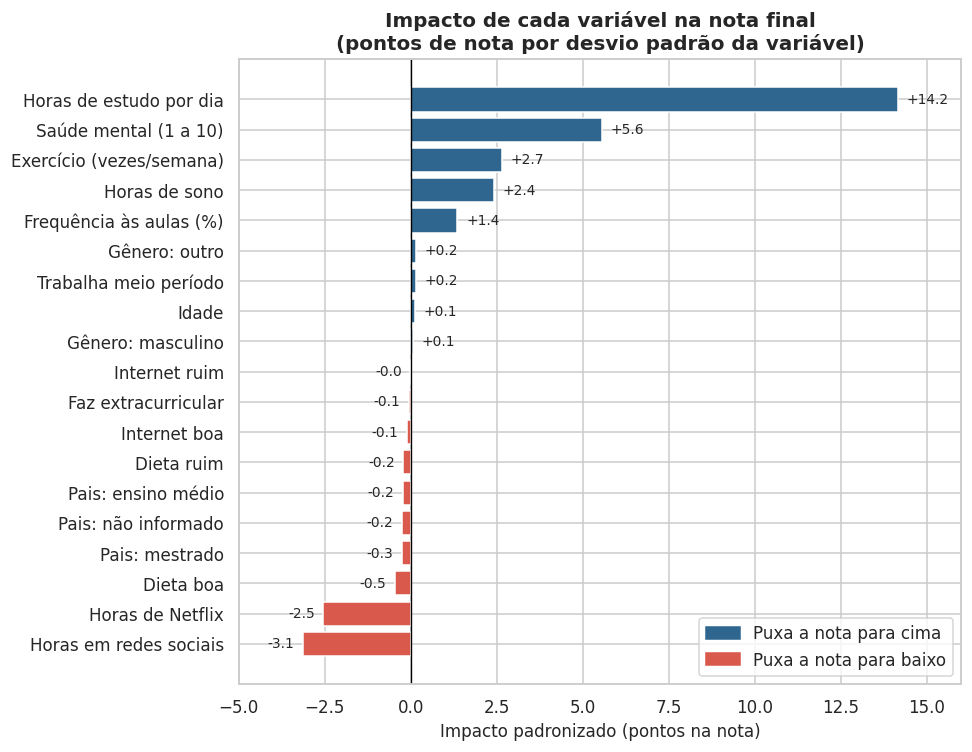

In [ ]:
ordenado = coeficientes.sort_values("impacto_padronizado")
cores = [VERMELHO if valor < 0 else AZUL for valor in ordenado["impacto_padronizado"]]

figura, eixo = plt.subplots(figsize=(9, 7))
barras = eixo.barh(ordenado.index, ordenado["impacto_padronizado"], color=cores)
eixo.axvline(0, color="black", linewidth=0.9)

eixo.set_title("Impacto de cada variável na nota final\n(pontos de nota por desvio padrão da variável)")
eixo.set_xlabel("Impacto padronizado (pontos na nota)")
eixo.set_xlim(-5, 16)

for barra, valor in zip(barras, ordenado["impacto_padronizado"]):
    deslocamento = 0.25 if valor >= 0 else -0.25
    eixo.text(valor + deslocamento, barra.get_y() + barra.get_height() / 2,
              f"{valor:+.1f}", va="center",
              ha="left" if valor >= 0 else "right", fontsize=9)

barra_positiva = plt.Rectangle((0, 0), 1, 1, color=AZUL)
barra_negativa = plt.Rectangle((0, 0), 1, 1, color=VERMELHO)
eixo.legend([barra_positiva, barra_negativa], ["Puxa a nota para cima", "Puxa a nota para baixo"],
            loc="lower right")

plt.tight_layout()
plt.show()

O modelo separa as 19 variáveis em 9 com impacto positivo e 10 com impacto negativo. A leitura abaixo usa o coeficiente padronizado, que já está na mesma unidade para todas.

**Variáveis com impacto positivo na nota**

| Variável | Coeficiente | Impacto padronizado |
|---|---|---|
| Horas de estudo por dia | +9,53 | +14,15 |
| Saúde mental (1 a 10) | +1,95 | +5,57 |
| Exercício (vezes/semana) | +1,32 | +2,66 |
| Horas de sono | +1,98 | +2,42 |
| Frequência às aulas (%) | +0,14 | +1,36 |
| Gênero: outro | +0,81 | +0,17 |
| Trabalha meio período | +0,37 | +0,15 |
| Idade | +0,05 | +0,12 |
| Gênero: masculino | +0,13 | +0,07 |

Horas de estudo domina o grupo. O coeficiente bruto de 9,53 significa que cada hora diária a mais vale quase 10 pontos na prova, mantendo todo o resto constante, e o impacto padronizado de 14,15 responde por 53% de toda a força positiva do modelo.

Saúde mental vem em segundo, com 5,57. Cada ponto na autoavaliação vale cerca de 2 pontos na nota, e o efeito sobrevive depois de descontar as horas de estudo. Isso confirma o que a seção 2.4 sugeria: não é apenas reflexo de quem está bem estudar mais.

Exercício (2,66) e sono (2,42) formam um patamar bem mais modesto, e frequência às aulas fecha com 1,36. O coeficiente bruto de 0,14 por ponto percentual parece pequeno, mas a distância entre um aluno com 70% e outro com 95% de presença dá uns 3,5 pontos de nota.

As quatro últimas da tabela, gênero, trabalho de meio período e idade, ficam abaixo de 0,2 e são indistinguíveis de zero. O modelo concorda com o que os testes de hipótese já tinham mostrado nas seções 2.2 e 3.3.

**Variáveis com impacto negativo na nota**

| Variável | Coeficiente | Impacto padronizado |
|---|---|---|
| Horas em redes sociais | -2,69 | -3,14 |
| Horas de Netflix | -2,32 | -2,54 |
| Dieta boa | -0,96 | -0,46 |
| Pais: mestrado | -0,70 | -0,26 |
| Pais: não informado | -0,84 | -0,24 |
| Pais: ensino médio | -0,45 | -0,22 |
| Dieta ruim | -0,55 | -0,21 |
| Internet boa | -0,22 | -0,11 |
| Faz extracurricular | -0,11 | -0,05 |
| Internet ruim | -0,03 | -0,01 |

Só duas variáveis puxam a nota para baixo de forma relevante, e são as duas de lazer digital. Redes sociais custa 2,69 pontos por hora diária e Netflix 2,32. Somadas, chegam a 5,68 de impacto padronizado, o que as coloca como o segundo bloco mais forte do modelo inteiro, atrás apenas das horas de estudo.

As outras oito ficam todas abaixo de meio ponto. Dieta, escolaridade dos pais, qualidade da internet e participação em extracurricular não deveriam entrar em nenhuma política pública com base nestes dados.

Vale um alerta de leitura sobre elas. Tanto "dieta boa" quanto "dieta ruim" aparecem com coeficiente negativo, o que à primeira vista não faz sentido. A explicação é a categoria de referência: como usamos `drop_first=True`, as duas estão sendo comparadas com "dieta regular", que ficou de fora. O que a tabela diz é que as três categorias de dieta são equivalentes, não que comer bem prejudique a nota. O mesmo vale para as três linhas de escolaridade dos pais e para as duas de internet.

**Comparando os dois grupos**

Somando o impacto padronizado em valor absoluto, as positivas totalizam 26,7 contra 7,2 das negativas. Os hábitos que ajudam pesam quase quatro vezes mais que os que atrapalham, e dentro do lado positivo as horas de estudo respondem sozinhas por mais da metade.

### 4.2 O modelo linear é bom o bastante?

A regressão parte de uma suposição forte: a de que os efeitos apenas se somam, cada variável contribuindo com uma quantidade fixa de pontos. Se a realidade não for assim, ela vai errar de forma sistemática.

Para testar isso, rodamos uma Random Forest com exatamente os mesmos dados. Ela funciona de um jeito bem diferente: constrói centenas de árvores de decisão, cada uma repartindo os alunos por faixas das variáveis, e tira a média das respostas. Como não assume linha reta nenhuma, ela consegue capturar duas coisas que a regressão não capta. Relações que mudam de intensidade ao longo da escala, como se as primeiras horas de estudo valessem mais que as últimas. E combinações entre variáveis, como se dormir bem só ajudasse quem já estuda bastante.

A lógica do teste é simples. Se a floresta ganhar, existe algo além de soma de efeitos e a regressão está perdendo informação. Se perder, a relação é mesmo linear e ficamos com o modelo mais simples e explicável.

In [ ]:
comparacao_modelos = pd.DataFrame([
    avaliar("Baseline (média)", DummyRegressor(strategy="mean")),
    avaliar("Regressão linear", LinearRegression()),
    avaliar("Random Forest", RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1)),
]).set_index("modelo")

print(comparacao_modelos.to_string(float_format=lambda valor: f"{valor:.3f}"))

                  R² treino  R² teste   RMSE    MAE
modelo                                             
Baseline (média)      0.000    -0.005 16.053 12.380
Regressão linear      0.902     0.897  5.146  4.189
Random Forest         0.980     0.853  6.147  4.924


A floresta ficou atrás em todas as métricas: R² de 0,853 contra 0,897 da regressão, RMSE de 6,15 contra 5,15 e MAE de 4,92 contra 4,19.

O mais revelador está na coluna de treino. Ela acerta quase tudo nos alunos que viu, 0,980, e cai para 0,853 nos que não viu. Essa distância entre treino e teste é a assinatura do modelo que decorou a amostra em vez de aprender o padrão. A regressão vai de 0,902 para 0,897, praticamente sem perda.

A explicação está na suposição de cada modelo. A floresta rende quando a relação muda de intensidade ao longo da escala ou quando uma variável só faz efeito na presença de outra. Como aqui os efeitos apenas se somam, ela gasta capacidade procurando um padrão que não existe e acaba se ajustando ao ruído.

Ficamos com a regressão linear como modelo final. Ela é mais precisa.

### 4.3 Diagnóstico dos resíduos

Resíduo é a diferença entre a nota real do aluno e a que o modelo previu. Um R² alto e um erro médio baixo dizem que o modelo acerta na média, mas não garantem que ele acerte por igual. Ele pode estar indo bem com a maioria e errando de forma sistemática num pedaço específico da turma, e é isso que esta seção procura.

Olhamos três coisas. Se os erros se distribuem em torno do zero, o que mostra que o modelo não puxa a previsão sistematicamente para cima nem para baixo. Se o tamanho do erro é parecido em toda a escala, ou se ele cresce nas notas altas ou baixas, caso em que o modelo seria confiável só numa faixa. E se sobram erros muito grandes, que indicariam alunos com perfil que o modelo não captura.

Aproveitamos também para resolver o teto de 100 que apareceu no tratamento. Como a regressão não sabe que a nota tem limite, ela prevê valores acima disso para alguns alunos.

In [ ]:
print(f"Previsões acima de 100: {(previsto > 100).sum()} (máxima de {previsto.max():.1f})")

# A nota não pode passar de 100, então cortamos as previsões no intervalo válido.
previsto_ajustado = np.clip(previsto, 0, 100)
residuos = y_teste - previsto_ajustado

print(f"\nDepois de limitar as previsões ao intervalo válido:")
print(f"R²  : {r2_score(y_teste, previsto_ajustado):.3f}")
print(f"MAE : {mean_absolute_error(y_teste, previsto_ajustado):.2f} pontos")
print(f"\nErro médio (deveria ficar perto de zero): {residuos.mean():.3f}")

Previsões acima de 100: 3 (máxima de 106.9)

Depois de limitar as previsões ao intervalo válido:
R²  : 0.898
MAE : 4.14 pontos

Erro médio (deveria ficar perto de zero): 0.006


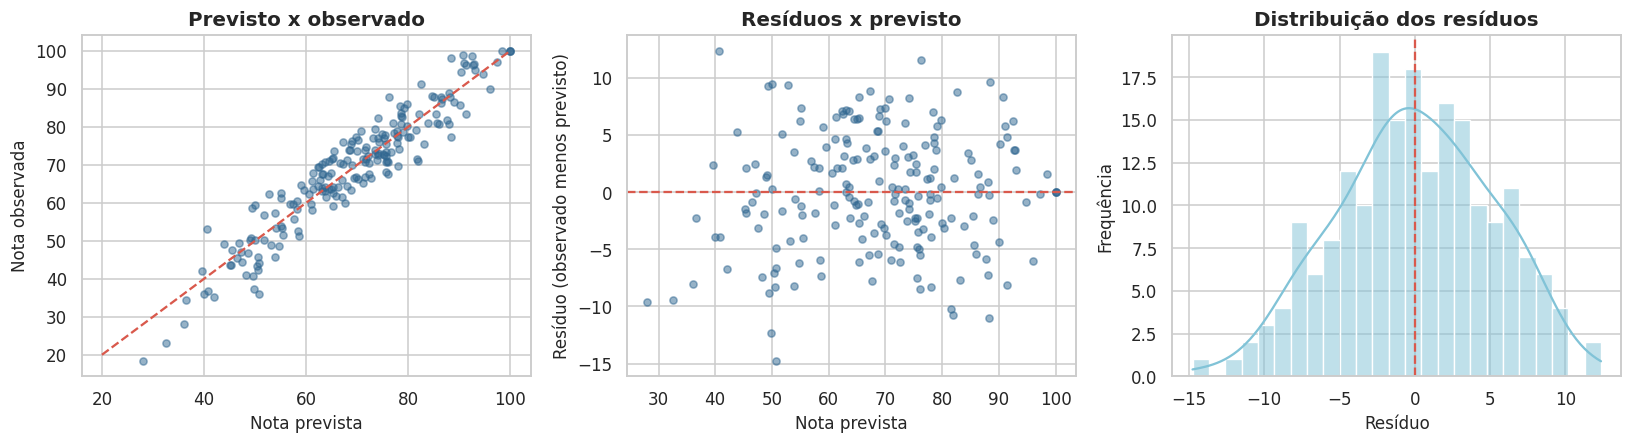

In [ ]:
figura, eixos = plt.subplots(1, 3, figsize=(15, 4.2))

eixos[0].scatter(previsto_ajustado, y_teste, alpha=0.5, s=22, color=AZUL)
eixos[0].plot([20, 100], [20, 100], color=VERMELHO, linestyle="--", linewidth=1.5)
eixos[0].set_title("Previsto x observado")
eixos[0].set_xlabel("Nota prevista")
eixos[0].set_ylabel("Nota observada")

eixos[1].scatter(previsto_ajustado, residuos, alpha=0.5, s=22, color=AZUL)
eixos[1].axhline(0, color=VERMELHO, linestyle="--", linewidth=1.5)
eixos[1].set_title("Resíduos x previsto")
eixos[1].set_xlabel("Nota prevista")
eixos[1].set_ylabel("Resíduo (observado menos previsto)")

sns.histplot(residuos, bins=25, kde=True, color=AZUL_CLARO, ax=eixos[2])
eixos[2].axvline(0, color=VERMELHO, linestyle="--", linewidth=1.5)
eixos[2].set_title("Distribuição dos resíduos")
eixos[2].set_xlabel("Resíduo")
eixos[2].set_ylabel("Frequência")

plt.tight_layout()
plt.show()

É o que acontece aqui, nos três aspectos.

A média dos resíduos ficou em 0,006, praticamente zero, então o modelo não puxa a previsão sistematicamente para nenhum lado. No primeiro gráfico, os pontos acompanham de perto a diagonal tracejada, que é onde eles cairiam se a previsão fosse exata.

No gráfico do meio os pontos formam uma faixa horizontal, sem funil e sem curva. Isso quer dizer que o modelo erra por igual em toda a escala, tanto para quem tira nota baixa quanto para quem tira nota alta, e não apenas numa faixa.

O histograma mostra os erros concentrados perto de zero e simétricos, com poucos casos nas pontas. Colocando em números: dos 200 alunos do conjunto de teste, 129 têm erro de até 5 pontos, apenas 7 passam de 10, e o pior caso de todos é 14,8.

O ajuste do teto era pequeno na prática. Só 3 alunos do teste recebiam previsão acima de 100, com máxima de 106,9, e limitar ao intervalo válido mudou pouco o R². Ainda assim é obrigatório na entrega: um modelo que devolve nota 107 numa prova que vale 100 perde credibilidade na primeira reunião, mesmo estando certo em tudo o mais.

Sobra um único ponto onde o modelo erra de forma sistemática, e ele é inevitável. Para os 48 alunos que tiraram exatamente 100, qualquer previsão só pode ficar abaixo ou igual, nunca acima, então o erro nesse grupo tem sempre o mesmo sinal.

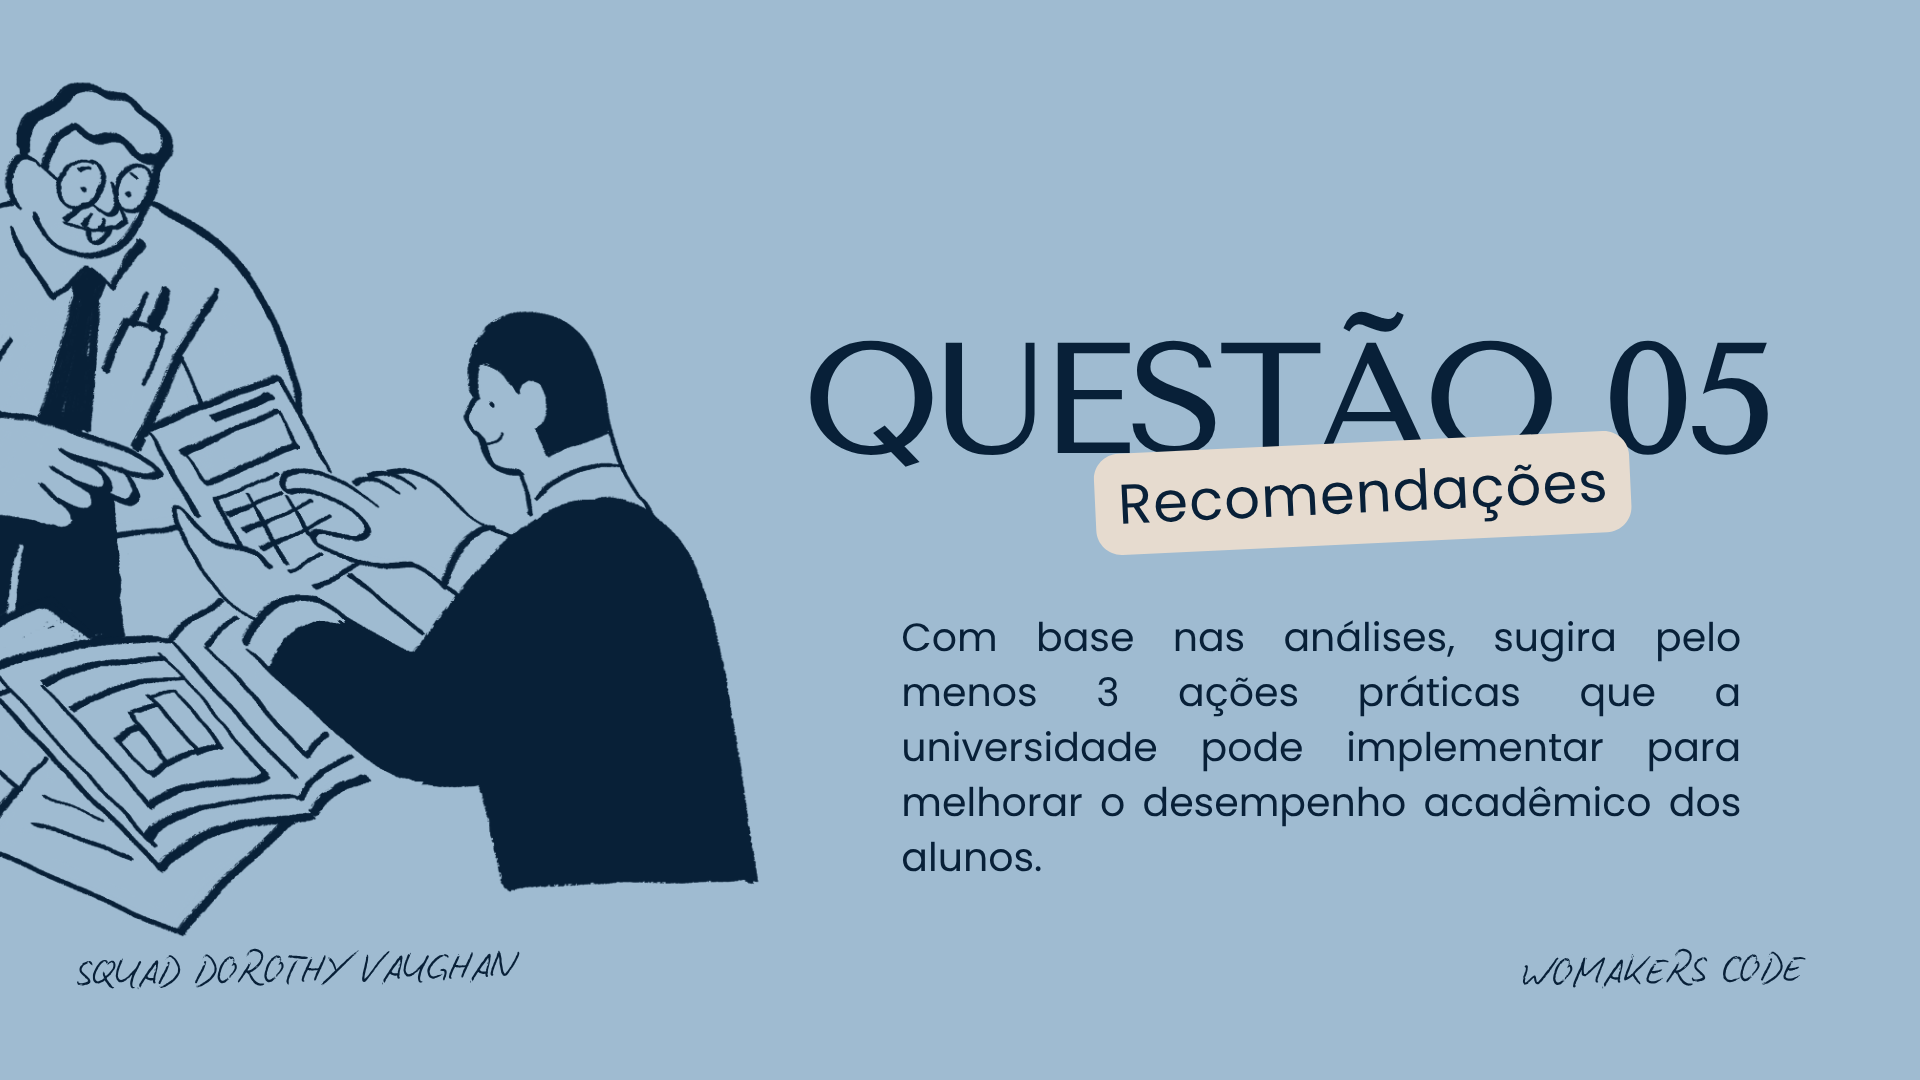

## 5. Recomendações

Três coisas ficaram claras: o que decide a nota é tempo de estudo, saúde mental tem peso próprio e as variáveis de contexto não separam ninguém. As recomendações abaixo saem daí, com o tamanho esperado de cada efeito segundo o modelo.

**1. Criar um programa de rotina de estudos com meta de horas, começando pelos 133 alunos que estudam menos de 2 horas por dia**

Esse grupo tira 45,6 de média e 94% deles ficam abaixo de 60. É onde o retorno esperado é maior: pelo modelo, levar um aluno de 1,5 para 3,5 horas diárias vale cerca de 19 pontos na prova.

Sala de estudo com horário fixo, monitoria por disciplina e acompanhamento semanal de carga são intervenções que produzem hora de estudo mensurável. Campanha de conscientização não gera esse registro, então nem daria para saber se funcionou.

**2. Ampliar o apoio psicológico e usar a autoavaliação de bem estar como gatilho de busca ativa**

São 301 alunos na faixa baixa de saúde mental, quase um terço da turma, com média 12,5 pontos abaixo da faixa alta. O modelo mostra que cada ponto na escala vale cerca de 2 pontos na nota mesmo depois de controlar horas de estudo, então não é apenas reflexo de quem estuda mais.

Sugerimos aplicar uma autoavaliação curta no início de cada semestre e acionar contato ativo para quem pontuar 3 ou menos. Há 33 alunos que combinam saúde mental baixa com menos de 2 horas de estudo, e esses deveriam entrar nos dois programas ao mesmo tempo.

**3. Tratar sono e atividade física como pauta acadêmica**

343 alunos dormem menos de 6 horas e 290 se exercitam no máximo uma vez por semana. Cada hora de sono vale 2 pontos e cada sessão semanal de exercício vale 1,3. Um aluno que sai de 5 para 7 horas de sono e passa a se exercitar três vezes por semana em vez de uma, ganha cerca de 6,6 pontos.

É o menor efeito das três primeiras recomendações, mas também o de menor custo, porque envolve mexer em decisões que a universidade já controla: revisar horário de provas, abrir a infraestrutura esportiva em horário compatível com quem trabalha, e revisar cronograma.

**4. Não segmentar apoio por perfil demográfico e socioeconômico**

Gênero, escolaridade dos pais, trabalho de meio período, qualidade da internet e dieta não mostraram efeito nenhum aqui, nem nos testes de hipótese nem no modelo. Se a universidade hoje direciona apoio por esses critérios, está gastando verba em quem talvez não precise e deixando de fora quem precisa.

A triagem que os dados sustentam é por comportamento: horas de estudo, saúde mental, sono e frequência às aulas. Todos são coletáveis com um formulário curto no início do semestre, e nenhum exige informação sensível sobre a família do aluno.

**Uma recomendação sobre o que não fazer**

Redes sociais e Netflix têm efeito negativo real, mas pequeno: as duas juntas acompanham menos de 6% da variação. Campanha de detox digital costuma ser o primeiro impulso de instituição nesse tipo de diagnóstico, e aqui seria esforço mal alocado. No máximo, o tema cabe como um tópico dentro de uma oficina de gestão de tempo, mas não como programa próprio.

**Como tratar**

O caminho correto é tratar cada recomendação como hipótese a testar: rodar um piloto com um grupo, manter um grupo de comparação e medir a diferença ao fim de um semestre. Isso também resolve a questão da causa, que a base atual não permite responder.

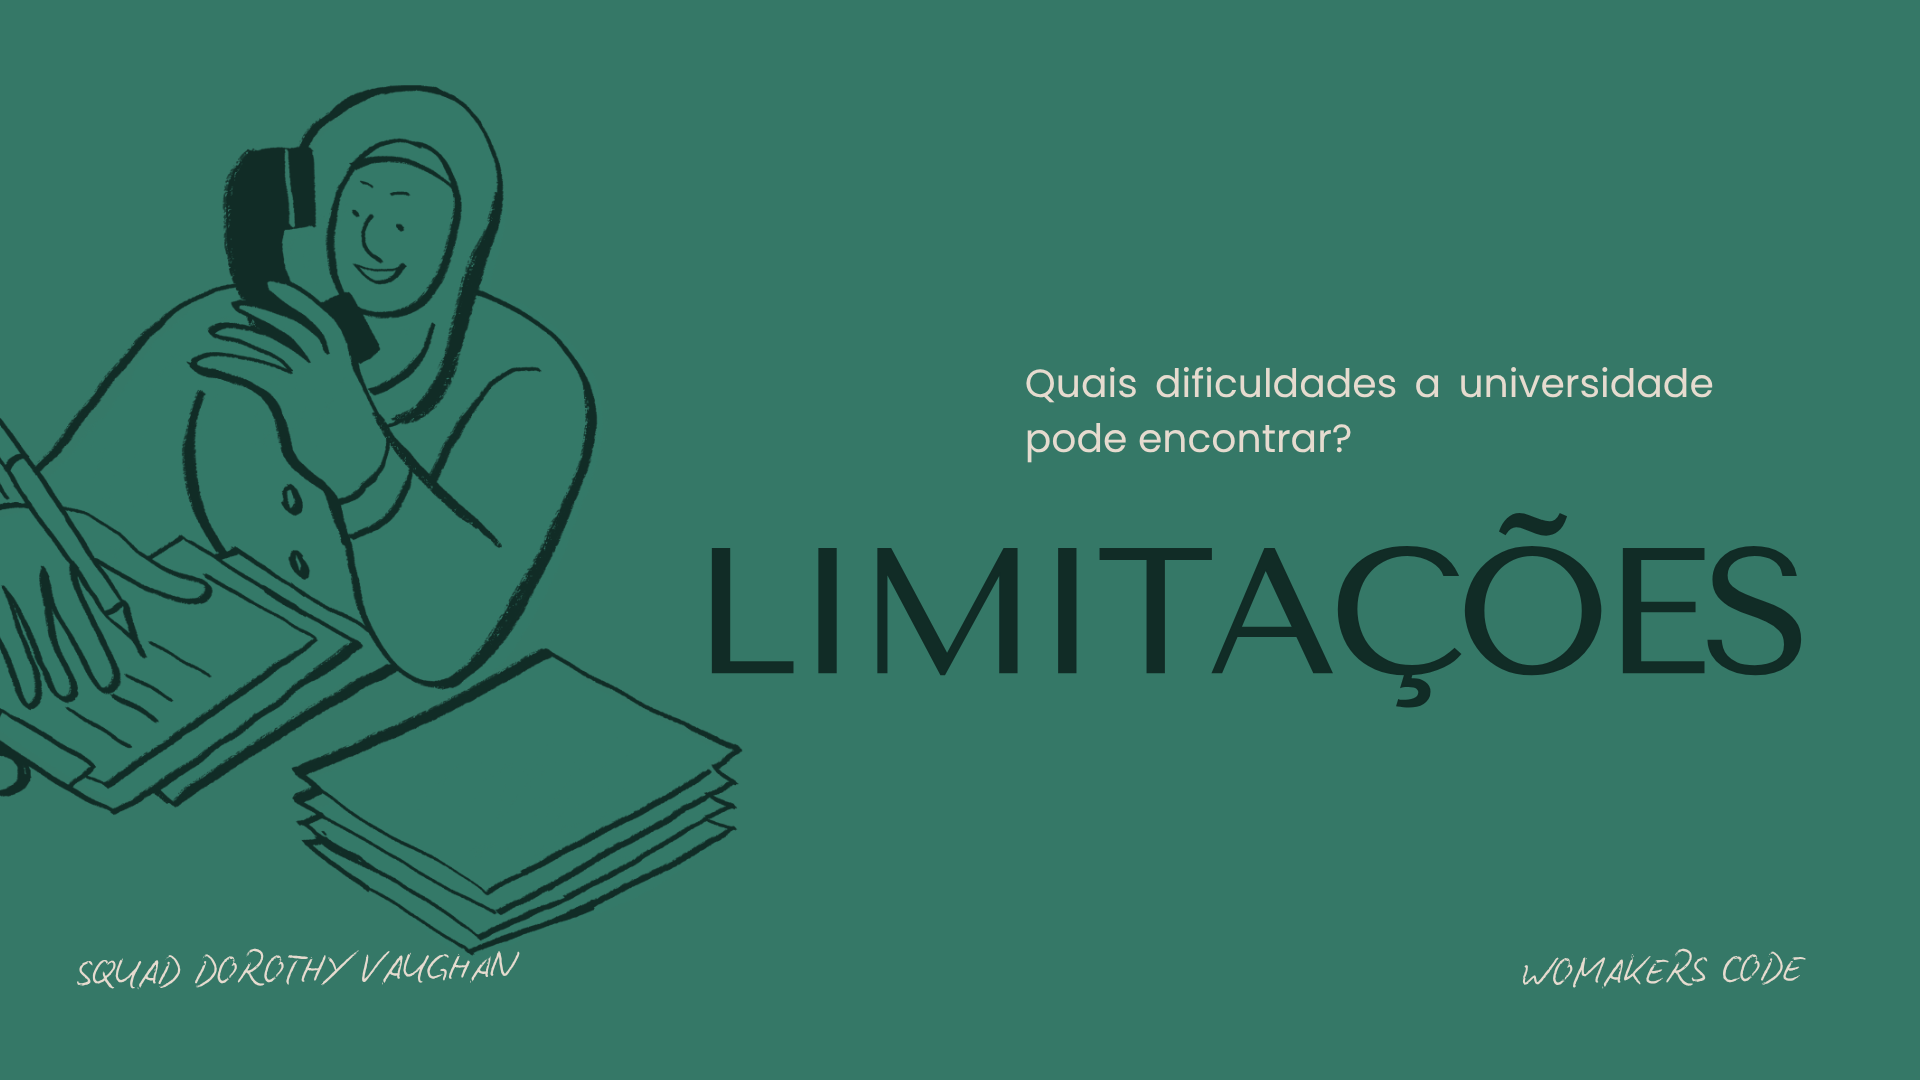

## 6. Limitações


1. Os dados são uma foto de um único momento (estudo transversal): Todas as informações foram coletadas de uma só vez. Por isso, vemos que certas coisas andam juntas (correlação), mas não conseguimos provar o que causa o que. Por exemplo: estar bem psicologicamente ajuda a tirar notas boas, mas tirar notas boas também melhora a saúde mental do estudante.    
3. A precisão do modelo é atipicamente alta: O modelo conseguiu explicar cerca de 90% da variação das notas apenas com os hábitos diários. Em turmas reais, o desempenho depende de muitos fatores que não foram medidos (qualidade das aulas, histórico escolar prévio, imprevistos no dia da prova).


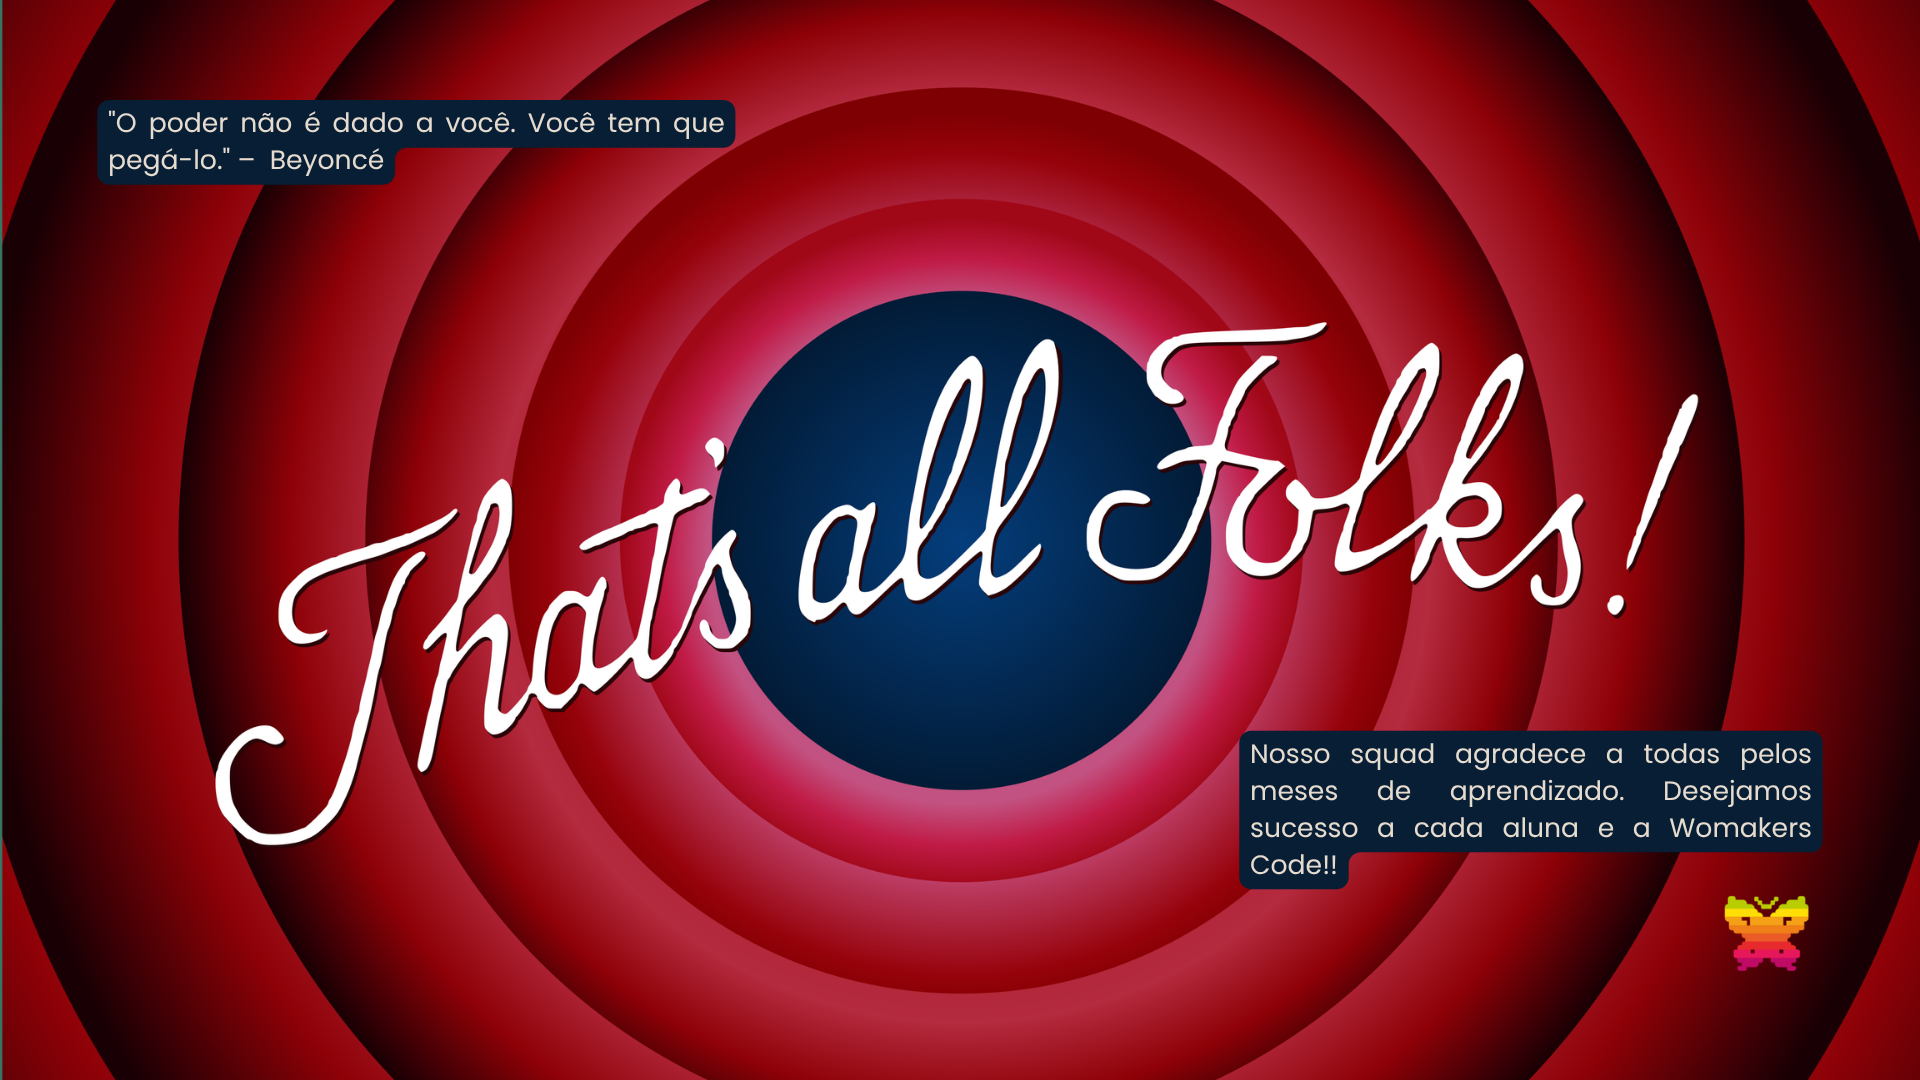

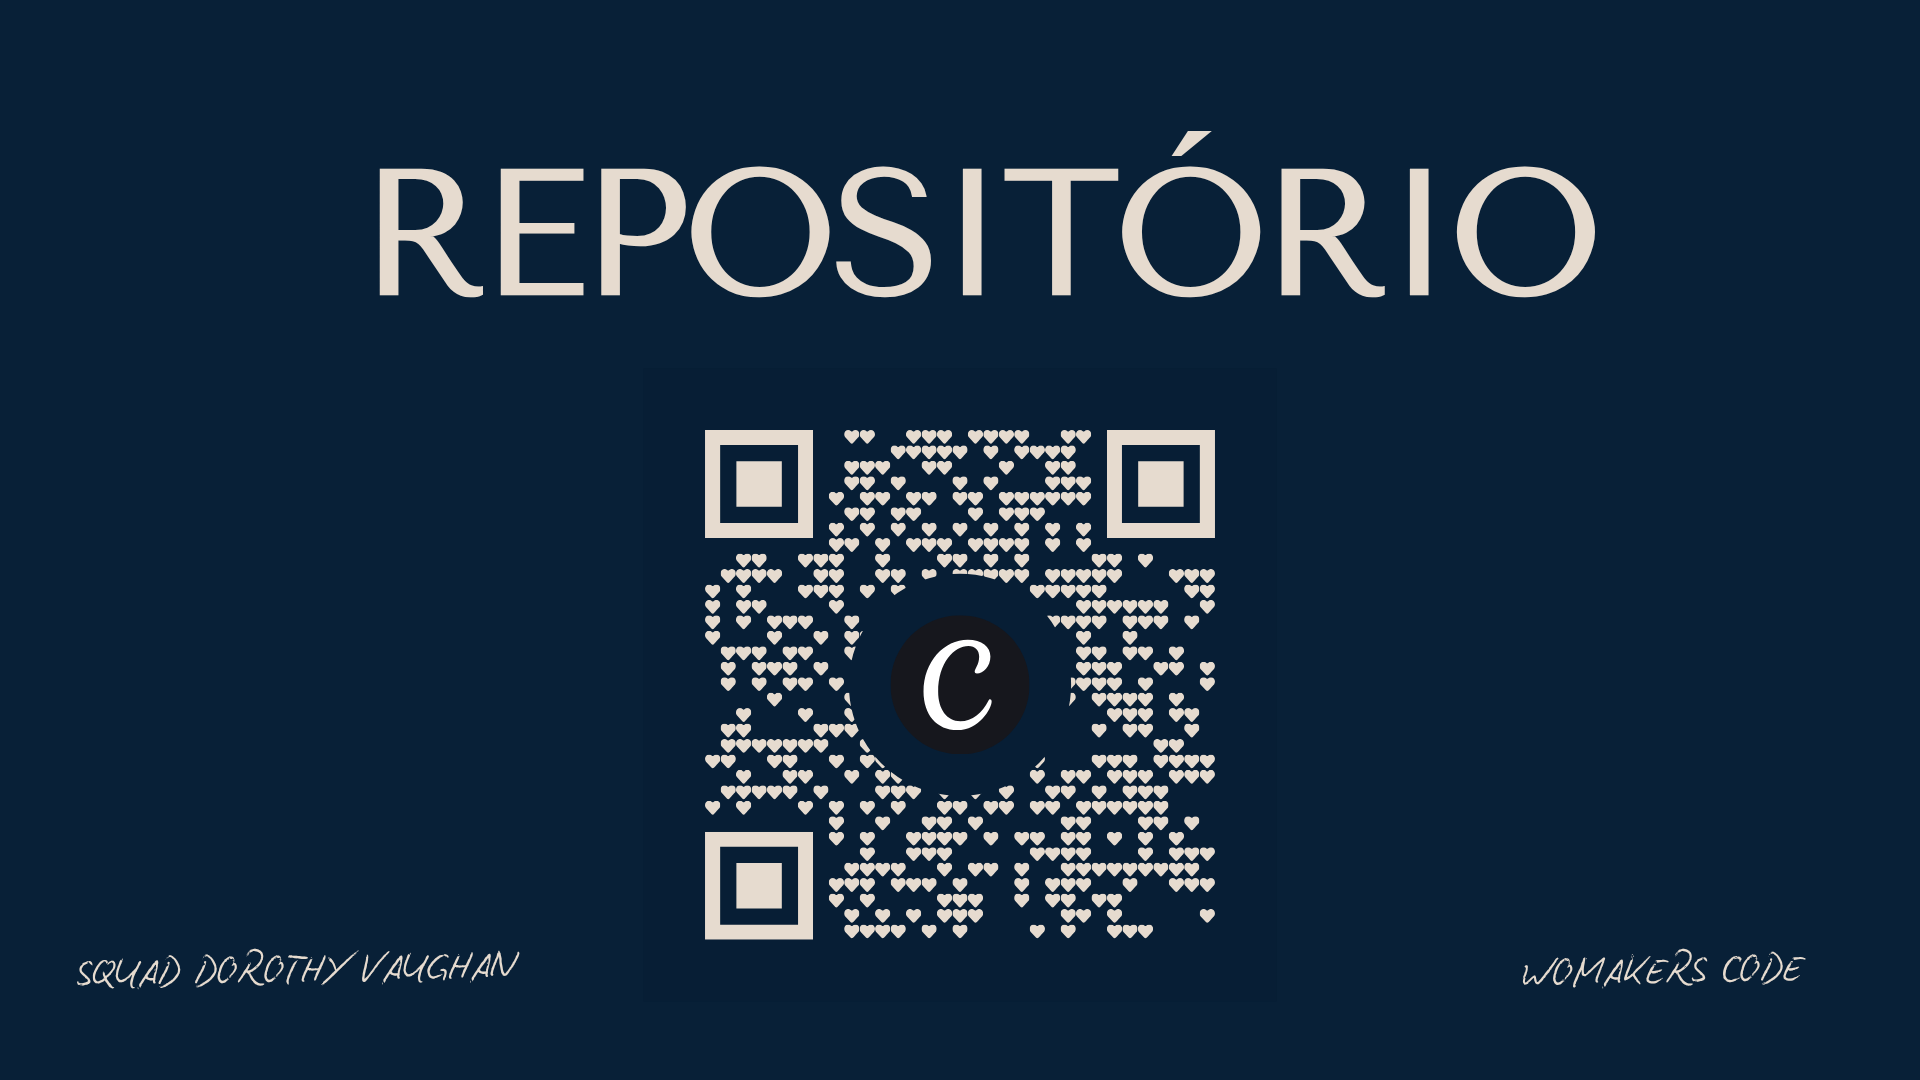